<a href="https://colab.research.google.com/github/estebangarcia9099-netizen/ENTREGABLES-BIT-ESTEBAN-GARCIA/blob/main/03_Datos%20%26%20Visualizaci%C3%B3n/Clase_13_An%C3%A1lisis_Exploratorio_De_Datos_(EDA)_Entregable.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller de Análisis Exploratorio de Datos (EDA)
## Caso de estudio: comercio electrónico, clientes y operación

**Nombre:** ______________________________________

---

## Propósito del taller

Asumir el rol de un equipo de analítica que recibe datos reales de una empresa y debe comprenderlos antes de tomar decisiones.

No existe una única ruta de análisis ni una respuesta predeterminada. Se debe decidir qué investigar, qué variables utilizar, qué transformaciones realizar y cómo comunicar sus hallazgos.

**Regla de trabajo:** no se considera suficiente ejecutar código o producir gráficos. Cada decisión debe tener una justificación y cada resultado importante debe interpretarse en su contexto.

## Dataset seleccionado

**Brazilian E-Commerce Public Dataset by Olist**

Fuente: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

El conjunto contiene información anonimizada de aproximadamente 100.000 pedidos realizados entre 2016 y 2018. Los datos están distribuidos en archivos CSV relacionados entre sí.

### Archivos disponibles

| Archivo | Información general |
|---|---|
| `olist_orders_dataset.csv` | Pedidos, estados y fechas del proceso |
| `olist_order_items_dataset.csv` | Artículos, vendedores, precios y flete |
| `olist_customers_dataset.csv` | Identificadores y ubicación de clientes |
| `olist_products_dataset.csv` | Categorías y características de productos |
| `olist_sellers_dataset.csv` | Identificadores y ubicación de vendedores |
| `olist_order_payments_dataset.csv` | Formas y valores de pago |
| `olist_order_reviews_dataset.csv` | Calificaciones y comentarios |
| `olist_geolocation_dataset.csv` | Coordenadas asociadas a códigos postales |
| `product_category_name_translation.csv` | Traducción de categorías de productos |

**Importante:** no es obligatorio utilizar los nueve archivos. Selecciona los que necesitas para responder una pregunta de análisis. Antes de unir tablas, investiga qué representa cada fila y qué relación existe entre ellas.

# Fase 1. Comprensión del problema

## 1.1 Conocer el contexto

1. ¿Qué tipo de organización o actividad económica representa este conjunto de datos?
Representa una plataforma de comercio electrónico (e-commerce) bajo el modelo de marketplace B2C (específicamente Olist, un agregador brasileño que conecta a miles de pequeños y medianos comercios/vendedores con consumidores finales a través de grandes canales digitales). La organización no necesariamente fabrica los productos, sino que intermedia la transacción, gestiona el flujo de pedidos y coordina la trazabilidad logística hasta la entrega.
2. ¿Qué procesos del negocio crees que pueden estudiarse con esta información?

**Ciclo completo de cumplimiento de pedidos:** Tiempos entre compra, aprobación de pago, despacho al transportista y entrega final al cliente frente a la fecha prometida.

**Gestión comercial y de portafolio:** Volumen de ventas, ticket promedio, estructura de precios, demanda por categorías de producto y concentración de ingresos por vendedor.

**Logística y distribución geográfica:** Costos de flete, rutas origen-destino (vendedor vs. cliente) y eficiencia de entrega por región o código postal.

**Medios de pago y conversión financiera:** Preferencia de métodos de pago (tarjeta de crédito, boleto bancario, vales), compras a cuotas y tasas de cancelación.

**Experiencia y satisfacción posventa:** Evolución de las calificaciones y análisis de sentimiento/motivos de queja en los comentarios escritos.
3. ¿Qué decisiones podría tomar una empresa a partir de un análisis de estos datos?

**Ajustar las promesas de entrega:** Recalibrar los algoritmos que calculan las entregas estimadas por región para evitar falsas expectativas que destruyen la calificación.

**Gestionar el desempeño de vendedores:**  capacitar vendedores que incumplen reiteradamente los plazos de despacho, o premiar con mayor visibilidad a los de mejor cumplimiento.

**Optimizar subsidios de envío:** Identificar categorías o zonas donde el flete representa un porcentaje excesivo del precio del producto para diseñar campañas de envío gratis o negociar tarifas con operadores logísticos.

**Focalizar estrategias comerciales y de retención:** Detectar categorías con alta demanda o estacionalidad para planificar campañas promocionales y programas de fidelización.
4. ¿Qué información crees que hace falta para comprender completamente el negocio?

**Márgenes y costos internos:** Comisiones cobradas por la plataforma a cada vendedor, costos reales pagados a las transportadoras (para saber si el flete genera ganancia o pérdida).

**Datos de comportamiento previo a la compra:** Visitas, clics, carritos abandonados y tasas de conversión, ya que el dataset solo registra pedidos ya creados.

## 1.2 Conectar el análisis con una perspectiva profesional

Piensa en tu formación, experiencia o área de interés.

**1. ¿Qué aspecto del negocio te resulta más interesante investigar?**

La intersección entre el desempeño comercial/operativo y la satisfacción del cliente: entender cómo la experiencia real de compra y entrega (cumplimiento de tiempos y estructura de precios/fletes) impacta directamente la percepción de valor, la reputación de la plataforma y el potencial de recompra.

**2. ¿Qué problema real de esa área podrías analizar con estos datos?**

El deterioro de la satisfacción del cliente (caída en las calificaciones a 1 o 2 estrellas) y la pérdida de confianza en el canal, determinando cuánto de esa insatisfacción proviene de retrasos logísticos frente a problemas de precio/flete o incumplimiento de vendedores específicos.

**3. ¿Qué archivo podría contener información útil para investigarlo?**

olist_orders_dataset.csv (para medir el cumplimiento real vs. estimado de entrega y detectar pedidos cancelados).

olist_order_reviews_dataset.csv (para medir el nivel de satisfacción mediante review_score y revisar comentarios).

olist_order_items_dataset.csv (para evaluar el valor de la compra, el peso del flete sobre el precio y el desempeño individual de cada seller_id).

**4. ¿Qué variable o indicador les gustaría comprender?**

Calificación promedio de satisfacción (review_score) y tasa de detractores (% de reseñas con 1 estrella).

Desviación en días de entrega (delay_days): diferencia en días calendario entre la entrega real (order_delivered_customer_date) y la promesa comercial (order_estimated_delivery_date).

Peso relativo del flete (freight_ratio): proporción que representa el costo de envío sobre el valor del producto (freight_value / price).

**5. ¿Por qué el resultado de tu análisis sería útil para alguien que debe tomar decisiones?**

Porque permite pasar de intuiciones generales a acciones priorizadas con impacto directo en retención y reputación: en lugar de invertir presupuesto tratando de bajar indiscriminadamente los costos de envío, un gerente comercial o de operaciones sabrá exactamente a partir de cuántos días de retraso se desploma la satisfacción del cliente y qué porcentaje de pedidos o vendedores concentran el problema.

**Define una perspectiva inicial de análisis:**


In [2]:
# Analizar el impacto del cumplimiento en los tiempos de entrega y la estructura de costos de envío sobre la calificación de satisfacción del cliente en Olist,
#con el objetivo de identificar los umbrales críticos de retraso que detonan malas reseñas y priorizar acciones correctivas en la gestión comercial y logística.


# Fase 2. Selección y conocimiento de los datos

## 2.1 Selección de un único archivo

**1. ¿Qué pregunta de negocio quieres responder?**

Cuál es el nivel de cumplimiento en las fechas de entrega prometidas por Olist, qué porcentaje de pedidos sufren retrasos o cancelaciones y cómo evolucionaron los tiempos reales de entrega a lo largo del periodo analizado?

**2. ¿Qué archivo o archivos necesitan para responderla?**

Archivo único principal seleccionado: olist_orders_dataset.csv
Archivos complementarios (para el cruce analítico de satisfacción e ingresos): olist_order_items_dataset.csv y olist_order_reviews_dataset.csv

**3. ¿Por qué seleccionaron esos archivos y descartaron los demás?**

Por qué se eligieron: olist_orders_dataset.csv es el eje central transaccional del negocio; contiene el ciclo de vida completo de cada orden (compra, aprobación, despacho, entrega real y entrega estimada). Al sumarle order_items (valor económico y flete) y order_reviews (satisfacción), se cubre el núcleo operativo, financiero y de experiencia del cliente sin complejidad innecesaria.

Por qué se descartaron los otros 6 archivos: geolocation y customers aportan detalle espacial que no es necesario para evaluar el cumplimiento general de entregas; products y product_category_name_translation añaden granularidad de catálogo que dispersa el análisis inicial; sellers y order_payments responden a preguntas específicas de vendedores o medios de pago que salen del alcance de esta fase.

**4. ¿Qué representa una fila en cada archivo seleccionado?**

olist_orders_dataset.csv: Representa 1 pedido único (order_id) y su trazabilidad de estados y marcas de tiempo.

olist_order_items_dataset.csv: Representa 1 línea de artículo dentro de un pedido (si un pedido tiene 3 productos, ocupa 3 filas identificadas por order_id + order_item_id).

olist_order_reviews_dataset.csv: Representa 1 encuesta de satisfacción emitida (review_id), asociada a un pedido (aunque un mismo pedido puede tener más de 1 encuesta si se le reenvió la valoración).

**5. ¿Cuál podría ser la llave o identificador que permita relacionar los archivos?**

La columna order_id actúa como llave primaria (PK) en olist_orders_dataset.csv y como llave foránea (FK) en olist_order_items_dataset.csv

La columna order_id actúa como llave primaria (PK) en olist_orders_dataset.csv
**6. ¿Qué riesgos existen al unir tablas que tienen diferentes niveles de detalle?**

Duplicación de filas y distorsión de métricas (Producto Cartesiano): Si se cruza orders ($1$) con order_items ($N$) y al mismo tiempo con order_reviews ($N$) sin agrupar antes, un pedido con 2 productos y 2 reseñas generaría $2 \times 2 = 4$ filas, multiplicando artificialmente los montos de venta, los fletes y los conteos de pedidos.Pérdida de registros por uso incorrecto de INNER JOIN: Dado que existen 775 pedidos en orders sin ítems (cancelados o no disponibles) y 768 pedidos sin reseña, hacer un cruce estricto (INNER JOIN) elimina órdenes canceladas y sesga el análisis hacia pedidos completados.Inconsistencia en promedios: Calcular el promedio de calificación (review_score) sobre una tabla cruzada a nivel de ítem le daría mayor peso a los pedidos con muchos artículos frente a los pedidos de un solo artículo.

**Nombre del único archivo seleccionado y justificación:**

rchivo seleccionado: olist_orders_dataset.csv

Justificación: Es la tabla maestra y punto de partida obligatorio de todo el ecosistema Olist. Con 99,441 filas donde cada registro corresponde exactamente a 1 pedido único (sin duplicados en order_id), permite auditar de forma limpia y directa el embudo operativo de estados (delivered, shipped, canceled, unavailable), medir los tiempos reales de procesamiento y entrega frente a la promesa comercial (order_estimated_delivery_date), y sirve como tabla base (1:1) sobre la cual integrar posteriormente cualquier otra dimensión del negocio sin riesgo de duplicación.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
from google.colab import files
import pandas as pd

uploaded = files.upload()




Saving olist_orders_dataset.csv to olist_orders_dataset (1).csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset (1).csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset (1).csv


In [3]:
import pandas as pd
import glob
import os


if len(glob.glob('*orders_dataset*.csv')) == 0:
    from google.colab import files
    print("Selecciona los 3 archivos CSV (orders, order_items, order_reviews):")
    uploaded = files.upload()


orders = pd.read_csv(glob.glob('*orders_dataset*.csv')[0])
order_items = pd.read_csv(glob.glob('*order_items_dataset*.csv')[0])
order_reviews = pd.read_csv(glob.glob('*order_reviews_dataset*.csv')[0])


tablas = {
    "orders": orders,
    "order_items": order_items,
    "order_reviews": order_reviews
}

for nombre, df in tablas.items():
    print(f"Objeto: {nombre:<15} | Tipo: {type(df).__name__} | Filas: {df.shape[0]:>7,} | Columnas: {df.shape[1]}")

Selecciona los 3 archivos CSV (orders, order_items, order_reviews):


Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Objeto: orders          | Tipo: DataFrame | Filas:  99,441 | Columnas: 8
Objeto: order_items     | Tipo: DataFrame | Filas: 112,650 | Columnas: 7
Objeto: order_reviews   | Tipo: DataFrame | Filas:  99,224 | Columnas: 7


In [4]:
# Escribe aquí el código para identificar los objetos cargados y sus dimensiones.

tablas = {
    "orders": orders,
    "order_items": order_items,
    "order_reviews": order_reviews
}

for nombre, df in tablas.items():
    print(f"Objeto: {nombre:<15} | Tipo: {type(df).__name__} | Filas: {df.shape[0]:>7,} | Columnas: {df.shape[1]}")


Objeto: orders          | Tipo: DataFrame | Filas:  99,441 | Columnas: 8
Objeto: order_items     | Tipo: DataFrame | Filas: 112,650 | Columnas: 7
Objeto: order_reviews   | Tipo: DataFrame | Filas:  99,224 | Columnas: 7


## 2.2 Reconocimiento de la estructura

Explora los datos antes de modificarlos.

**1. ¿Cuántas filas y columnas tiene cada DataFrame?**

orders: 99,441 filas y 8 columnas.

order_items: 112,650 filas y 7 columnas.

order_reviews: 99,224 filas y 7 columnas.

**2. ¿Qué representa cada columna?**

A. orders (Pedidos)

order_id: Identificador único del pedido.

customer_id: Identificador único del cliente asociado a esa compra específica.

order_status: Estado actual del pedido (delivered, shipped, canceled, unavailable, etc.).

order_purchase_timestamp: Fecha y hora en que el cliente realizó la compra.

order_approved_at: Fecha y hora en que se aprobó el pago.

order_delivered_carrier_date: Fecha y hora en que el vendedor entregó el paquete al operador logístico/transportista.

order_delivered_customer_date: Fecha y hora real en que el cliente recibió el pedido.

order_estimated_delivery_date: Fecha límite estimada de entrega informada al cliente al momento de comprar.

B. order_items (Artículos por pedido)

order_id: Identificador del pedido al que pertenece el artículo.

order_item_id: Número secuencial del ítem dentro del mismo pedido (1, 2, 3...).

product_id: Identificador único del producto comprado (SKU).

seller_id: Identificador único del vendedor que despacha el producto.

shipping_limit_date: Fecha y hora límite que tiene el vendedor para entregar el paquete al transportista.

price: Precio unitario del artículo.

freight_value: Costo del envío/flete cobrado por ese artículo.

C. order_reviews (Reseñas y calificaciones)

review_id: Identificador único de la encuesta de satisfacción.

order_id: Identificador del pedido evaluado.

review_score: Calificación numérica otorgada por el cliente (escala entera de 1 a 5 estrellas).

review_comment_title: Título breve del comentario escrito por el cliente (opcional).

review_comment_message: Cuerpo del comentario escrito por el cliente (opcional).

review_creation_date: Fecha en que se envió la encuesta de satisfacción al cliente.

review_answer_timestamp: Fecha y hora en que el cliente respondió la encuesta.
**3. ¿Qué tipos de datos identifica Python?**

object (texto/cadenas): Todos los identificadores (order_id, customer_id, product_id, seller_id, review_id), las categorías (order_status), los textos libres (review_comment_title, review_comment_message) y todas las columnas de fechas/horas (que aún no están convertidas a tipo datetime64).

int64 (enteros): order_item_id (en order_items) y review_score (en order_reviews).

float64 (decimales): price y freight_value (en order_items).
**4. ¿Qué variables son numéricas, categóricas, temporales o identificadores?**

Tipo conceptualVariables en los 3 DataFrames

Identificadores (IDs)order_id, customer_id, product_id, seller_id, review_id, order_item_id (identificador secuencial dentro del pedido).

Numéricas (cuantitativas)price (continua), freight_value (continua).

Categóricas / Ordinalesorder_status (nominal), review_score (ordinal de 1 a 5).

Temporales (fechas/horas)order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date, shipping_limit_date, review_creation_date, review_answer_timestamp.

Texto librereview_comment_title, review_comment_message.

**5. ¿Qué variables parecen relevantes para la pregunta que planteaste?**

Llave de cruce: order_id.

Filtro de validez operativa: order_status (para trabajar con pedidos delivered).

Cálculo de retraso logístico: order_delivered_customer_date y order_estimated_delivery_date (además de order_purchase_timestamp para medir el tiempo total de tránsito).

Cálculo de impacto económico del envío: price y freight_value.

Variable objetivo (satisfacción): review_score.

**6. ¿Hay variables cuyo significado no sea evidente? ¿Cómo podrías investigarlo?**

customer_id: A primera vista parece un identificador único por persona, pero al compararlo con order_id (ambos tienen 99,441 valores únicos) se descubre que en Olist customer_id es un ID transaccional por pedido, no un ID histórico de cliente recurrente.

order_item_id: Aunque tiene tipo int64, no representa la cantidad comprada de un mismo producto en una fila (como quantity = 3), sino el índice secuencial de cada ítem dentro del carrito (fila 1 = ítem 1, fila 2 = ítem 2).

shipping_limit_date: No es la fecha de entrega al cliente, sino el plazo interno máximo del vendedor para despachar el paquete al operador logístico.

Revisando la documentación oficial y el diccionario de datos del dataset en Kaggle.Inspeccionando ejemplos concretos de un mismo order_id con múltiples filas en order_items (order_items[order_items['order_id'] == '...']) para comprobar si cada fila corresponde a un producto distinto o repetido.Comparando cronológicamente las fechas de un mismo pedido (purchase $\rightarrow$ approved $\rightarrow$ shipping_limit $\rightarrow$ delivered_carrier $\rightarrow$ delivered_customer).

**7. ¿Qué observaciones iniciales te generan curiosidad?**

Diferencia en el conteo de pedidos entre tablas: orders tiene 99,441 pedidos únicos, mientras que order_items tiene 98,666 (775 pedidos sin ítems) y order_reviews tiene 98,673 (768 pedidos sin encuesta). Resulta interesante verificar qué estados (canceled, unavailable) explican esos pedidos faltantes.

Duplicidad de encuestas: order_reviews tiene 99,224 filas para 98,673 pedidos únicos y 98,410 review_id únicos, lo que indica que algunos pedidos recibieron más de una encuesta o que una misma encuesta quedó vinculada a varios pedidos.

Alta ausencia de comentarios escritos frente a calificaciones completas: Mientras review_score está 100% completo, cerca del 59% de los clientes no escribe mensaje (review_comment_message) y el 88% no pone título, lo que sugiere investigar si quienes dejan comentarios escritos son principalmente los clientes insatisfechos (1 o 2 estrellas).

Todas las fechas cargadas como texto (object): Requieren conversión explícita a datetime antes de realizar cualquier resta de días o análisis temporal.



**Registro de observaciones:**


In [5]:
# Escribe aquí el código necesario para inspeccionar la estructura de los datos.

tablas = {
    "orders": orders,
    "order_items": order_items,
    "order_reviews": order_reviews
}

for nombre, df in tablas.items():
    print("=" * 65)
    print(f"DATAFRAME: {nombre.upper()} | Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
    print("=" * 65)

    resumen = pd.DataFrame({
        "Tipo_Dato": df.dtypes,
        "No_Nulos": df.notnull().sum(),
        "Nulos": df.isnull().sum(),
        "%_Nulos": (df.isnull().mean() * 100).round(2),
        "Valores_Unicos": df.nunique()
    })
    display(resumen)

    print(f"\nPrimeras 3 filas de {nombre}:")
    display(df.head(3))
    print("\n")


DATAFRAME: ORDERS | Dimensiones: 99,441 filas x 8 columnas


,Tipo_Dato,No_Nulos,Nulos,%_Nulos,Valores_Unicos
order_id,object,99441,0,0.00,99441
customer_id,object,99441,0,0.00,99441
order_status,object,99441,0,0.00,8
order_purchase_timestamp,object,99441,0,0.00,98875
order_approved_at,object,99281,160,0.16,90733
order_delivered_carrier_date,object,97658,1783,1.79,81018
order_delivered_customer_date,object,96476,2965,2.98,95664
order_estimated_delivery_date,object,99441,0,0.00,459



Primeras 3 filas de orders:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00




DATAFRAME: ORDER_ITEMS | Dimensiones: 112,650 filas x 7 columnas


,Tipo_Dato,No_Nulos,Nulos,%_Nulos,Valores_Unicos
order_id,object,112650,0,0.0,98666
order_item_id,int64,112650,0,0.0,21
product_id,object,112650,0,0.0,32951
seller_id,object,112650,0,0.0,3095
shipping_limit_date,object,112650,0,0.0,93318
price,float64,112650,0,0.0,5968
freight_value,float64,112650,0,0.0,6999


... (2 outputs left out)



DATAFRAME: ORDER_REVIEWS | Dimensiones: 99,224 filas x 7 columnas


,Tipo_Dato,No_Nulos,Nulos,%_Nulos,Valores_Unicos
review_id,object,99224,0,0.00,98410
order_id,object,99224,0,0.00,98673
review_score,int64,99224,0,0.00,5
review_comment_title,object,11568,87656,88.34,4527
review_comment_message,object,40977,58247,58.70,36159
review_creation_date,object,99224,0,0.00,636
review_answer_timestamp,object,99224,0,0.00,98248



Primeras 3 filas de order_reviews:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24


In [6]:
# Escribe aquí el código para explorar registros y valores de las variables.


# 1. Exploración de muestras aleatorias y finales para ver registros reales (no solo los primeros)
for nombre, df in [("orders", orders), ("order_items", order_items), ("order_reviews", order_reviews)]:
    print("=" * 70)
    print(f"MUESTRA ALEATORIA DE REGISTROS: {nombre.upper()}")
    print("=" * 70)
    display(df.sample(5, random_state=42))

# 2. Estadísticas descriptivas de variables numéricas (precios, fletes, ítems y calificaciones)
print("\n" + "=" * 70)
print("ESTADÍSTICAS DESCRIPTIVAS - VARIABLES NUMÉRICAS")
print("=" * 70)
print("\n--- order_items (price, freight_value, order_item_id) ---")
display(order_items[['order_item_id', 'price', 'freight_value']].describe().round(2))

print("\n--- order_reviews (review_score) ---")
display(order_reviews[['review_score']].describe().round(2))

# 3. Distribución de frecuencias en variables categóricas / discretas clave
print("\n" + "=" * 70)
print("DISTRIBUCIÓN DE VALORES CATEGÓRICOS Y DISCRETOS")
print("=" * 70)

print("\n--- Estados de los pedidos (orders['order_status']) ---")
estado_pedidos = pd.DataFrame({
    'Cantidad': orders['order_status'].value_counts(),
    'Porcentaje (%)': (orders['order_status'].value_counts(normalize=True) * 100).round(2)
})
display(estado_pedidos)

print("\n--- Distribución de calificaciones (order_reviews['review_score']) ---")
calificaciones = pd.DataFrame({
    'Cantidad': order_reviews['review_score'].value_counts().sort_index(),
    'Porcentaje (%)': (order_reviews['review_score'].value_counts(normalize=True).sort_index() * 100).round(2)
})
display(calificaciones)

print("\n--- Rango temporal de las compras (orders['order_purchase_timestamp']) ---")
print("Fecha mínima:", orders['order_purchase_timestamp'].min())
print("Fecha máxima:", orders['order_purchase_timestamp'].max())


MUESTRA ALEATORIA DE REGISTROS: ORDERS


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
52263,b9a6c5f5df52c7226ac85aee7524c27f,f160aaf480efdfa7268f0fa535f73e76,delivered,2018-06-12 20:07:44,2018-06-12 20:44:26,2018-06-13 13:09:00,2018-06-19 12:44:08,2018-07-17 00:00:00
46645,261e71d2349c713eafa9f3df5972b95d,d6708bbbd2d419475869a84e41f620a1,delivered,2018-01-20 12:15:57,2018-01-20 12:37:13,2018-01-25 21:42:52,2018-01-30 11:32:35,2018-02-15 00:00:00
37546,67b50899f52995848c427e361e10dde3,1b353c00c71689afba44554e43cc5a76,delivered,2018-06-16 21:24:10,2018-06-16 21:36:59,2018-06-21 13:55:00,2018-06-27 13:17:27,2018-07-16 00:00:00
94756,32733fc014b67ef70fa6039dd8c6ba82,ad66699beab381d0747605f108cc02b4,delivered,2017-08-30 21:12:28,2017-08-31 02:50:24,2017-09-12 20:16:46,2017-09-25 17:53:23,2017-09-22 00:00:00
14771,39a70e9e9b729b11dee34ac12478597f,20c678bfce3c8252288f70dd2bee5e51,delivered,2017-08-10 21:26:25,2017-08-10 21:44:13,2017-08-11 19:11:16,2017-08-22 16:45:00,2017-09-12 00:00:00


MUESTRA ALEATORIA DE REGISTROS: ORDER_ITEMS


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
107777,f4ee4273538924bda6212f5948e80fde,1,69455f41626a745aea9ee9164cb9eafd,7d13fca15225358621be4086e1eb0964,2018-06-19 09:18:15,180.00,20.45
2391,056349f85a73d794119c4286c95a52de,1,af35be35db4ad0dc288b571453337376,d20b021d3efdf267a402c402a48ea64b,2017-03-09 14:35:09,10.99,16.05
77829,b124967afcc82ef17ec41020fe2a9136,1,12e6d0f655986ceff00c74658dec97b1,3be634553519fb6536a03e1358e9fdc7,2018-06-06 17:18:09,49.99,8.88
99819,e257ae8610fb4fb68a1f459c3a4b1f51,1,a50acd33ba7a8da8e9db65094fa990a4,8581055ce74af1daba164fdbd55a40de,2017-05-18 08:02:19,117.30,14.43
41297,5e114d8e3840661abc3d9c4820f427b3,1,5cca3efb9521cc1d7099d610d4a12017,3d871de0142ce09b7081e2b9d1733cb1,2018-05-03 18:15:09,58.90,13.77


MUESTRA ALEATORIA DE REGISTROS: ORDER_REVIEWS


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
90252,406e32984dd5273582105460a79571af,e00ed9d20c3479f9f0e9727ca9d60946,5,NaN,NaN,2017-12-22 00:00:00,2017-12-22 21:10:19
24436,3bca8d9922bed47eb96f23d121945290,3b5351f5f99b46339212291661a9d226,5,NaN,Cumpriu o acordado!,2018-04-10 00:00:00,2018-04-13 01:57:05
11313,65895b807ac5dfe062c82400b3f210b8,f395e98fb5c1c6ce1306e80de2fe125b,4,NaN,NaN,2017-04-20 00:00:00,2017-04-21 11:31:32
75442,2a6faa65a6e893105c60b1018d40e14a,57899333b5e286632bd2599d3f7864ce,5,NaN,NaN,2018-04-06 00:00:00,2018-04-07 00:34:14
7217,a738aa683a09dc5979abc7d9c2cc8029,0cc76fbe09687fda664178e9fc6c404f,5,NaN,NaN,2018-01-07 00:00:00,2018-01-08 13:48:20


... (5 outputs left out)

,Cantidad,Porcentaje (%)
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00



--- Distribución de calificaciones (order_reviews['review_score']) ---


,Cantidad,Porcentaje (%)
review_score,,
1,11424,11.51
2,3151,3.18
3,8179,8.24
4,19142,19.29
5,57328,57.78



--- Rango temporal de las compras (orders['order_purchase_timestamp']) ---
Fecha mínima: 2016-09-04 21:15:19
Fecha máxima: 2018-10-17 17:30:18



# Apartado de apoyo. ¿Cómo unir tablas en Pandas?

Aunque el EDA principal se desarrolla sobre un único archivo, en un proyecto real puede ser necesario combinar información que está distribuida en varias tablas.

En Olist, por ejemplo, los pedidos y los datos de clientes se encuentran en archivos diferentes. Para analizarlos conjuntamente, se necesita identificar una columna que exista en ambas tablas y represente la misma entidad.

## Conceptos que debes comprender

- **Llave:** columna que permite relacionar registros entre tablas. Por ejemplo, `customer_id`.
- **Tabla izquierda (`left`):** DataFrame que se coloca primero en `merge`.
- **Tabla derecha (`right`):** DataFrame que se incorpora.
- **Tipo de unión (`how`):** define qué registros se conservan.

| Tipo | ¿Qué conserva? |
|---|---|
| `inner` | Solo las filas cuya llave aparece en ambas tablas. |
| `left` | Todas las filas de la tabla izquierda y las coincidencias de la derecha. |
| `right` | Todas las filas de la tabla derecha y las coincidencias de la izquierda. |
| `outer` | Todas las filas de ambas tablas; donde no hay coincidencia aparecen valores faltantes. |

## Estructura general

La función de Pandas utilizada es `merge()`:

```python
df_resultado = pd.merge(
    df_izquierdo,
    df_derecho,
    on="columna_llave",
    how="left"
)
```

Si las columnas que relacionan las tablas tienen nombres diferentes, se pueden utilizar `left_on` y `right_on`:

```python
df_resultado = pd.merge(
    df_izquierdo,
    df_derecho,
    left_on="id_tabla_1",
    right_on="id_tabla_2",
    how="inner"
)
```

## Antes de unir tablas, analiza

**1. ¿Qué representa una fila en cada DataFrame?**

orders: Representa 1 pedido único (order_id), registrando su estado actual y sus marcas de tiempo logísticas.

order_items: Representa 1 línea de artículo dentro de un pedido (order_id + order_item_id), con su precio unitario y costo de envío individual.

order_reviews: Representa 1 encuesta de satisfacción emitida (review_id), asociada a un pedido.

**2. ¿Cuál es la llave que relaciona las tablas?**

La columna order_id es el identificador común que conecta las tres tablas (orders, order_items y order_reviews).

**3. ¿La llave es única en una tabla, en ambas o en ninguna?**
La llave order_id es única únicamente en una tabla (orders) y se repite en las otras dos:

En orders: es 100% única (99,441 filas = 99,441 order_id únicos). Actúa como Llave Primaria (PK).

En order_items: no es única (112,650 filas para 98,666 order_id únicos), porque un pedido puede contener varios productos. Actúa como Llave Foránea (FK).

En order_reviews: no es única (99,224 filas para 98,673 order_id únicos), ya que existen ~547 pedidos que recibieron más de una encuesta de calificación. Actúa como Llave Foránea (FK).

**4. ¿La relación es uno a uno, uno a muchos o muchos a muchos?**

orders $\leftrightarrow$ order_items: Relación Uno a Muchos ($1:N$) (1 pedido puede tener $1$ o más artículos).orders $\leftrightarrow$ order_reviews: Relación Uno a Muchos ($1:N$) en los datos crudos (1 pedido tiene generalmente $1$ reseña, pero en algunos casos $2$ o $3$ encuestas). (Si se deduplica order_reviews por pedido antes de unir, pasa a ser Uno a Uno ($1:1$)).order_items $\leftrightarrow$ order_reviews (si se unen directamente sin agregar): Relación Muchos a Muchos ($N:M$), lo cual es peligroso porque genera un producto cartesiano.

**5. ¿Qué tipo de unión responde mejor a la pregunta de análisis?**

Para responder "¿Cómo impactan los retrasos en la entrega y el costo relativo del flete sobre la calificación de satisfacción (review_score)?":

Tipo de unión recomendado: LEFT JOIN (how='left') tomando como tabla izquierda (base) a orders (filtrada por pedidos delivered o manteniendo todos los pedidos para auditar pérdidas).

Estrategia correcta de granularidad: Antes de unir, se debe agregar (resumir) order_items a nivel de order_id (sumando price, sumando freight_value y contando order_item_id) y deduplicar order_reviews a 1 registro por order_id (conservando la reseña más reciente o el promedio). Así, las tres tablas quedan a nivel de 1 fila = 1 pedido y el LEFT JOIN preserva el 100% de los pedidos sin distorsionar métricas.

**6. ¿La unión puede duplicar registros? ¿Cómo lo comprobarías?**

Sí, puede duplicar registros si se unen las tablas directamente sin agrupar o deduplicar antes:Al unir orders (99,441) con order_items (112,650), los pedidos con múltiples artículos se multiplican por la cantidad de ítems que contengan.Si además se cruza directamente con order_reviews (99,224) sin deduplicar, un pedido con 3 artículos y 2 reseñas se convierte en $3 \times 2 = 6$ filas, inflando artificialmente las ventas, los fletes y el peso de su calificación.

Comparando el número de filas (len(df_unido)) contra el número de order_id únicos (df_unido['order_id'].nunique()): si len(df_unido) > df_unido['order_id'].nunique(), hay duplicación de pedidos.

Verificando las sumas de control antes y después del cruce: order_items['price'].sum() debe ser exactamente igual a df_unido['total_price'].sum().

**7. ¿Cuántas filas había antes y cuántas después de unir las tablas?**

Antes de la unión (tablas originales):

orders: 99,441 filas

order_items: 112,650 filas

order_reviews: 99,224 filas

Después de la unión (según el método aplicado):

Escenario A — Unión profesional agregada a nivel de pedido (LEFT JOIN desde orders con items agrupados y reviews deduplicados): 99,441 filas (se mantiene exactamente 1 fila por cada pedido de orders, sin duplicados ni pérdida de registros).

Escenario B — Unión directa (LEFT JOIN crudo sin agrupar ni deduplicar): 114,092 filas (resultado de multiplicar los pedidos con varios ítems por los pedidos con múltiples reseñas; si se usa INNER JOIN crudo, quedan 112,372 filas).

**Advertencia:** una unión técnicamente correcta puede producir resultados incorrectos si no se comprende el nivel de detalle de cada tabla. Por ejemplo, un pedido puede tener varios artículos; al unir pedidos con artículos, el pedido aparecerá en varias filas. Esto no necesariamente es un error: depende de qué representa cada fila en el resultado.

## Ejercicio de comprensión (no hace parte obligatoria del EDA)

Imagina que tienes una tabla de pedidos y otra de clientes.

**- ¿Qué columna podría relacionarlas?**

La columna customer_id (que funciona como llave foránea en la tabla de pedidos y llave primaria en la tabla de clientes).

**- Si quieres conservar todos los pedidos, incluso aquellos que no tengan coincidencia en la tabla de clientes, ¿qué tipo de unión elegirías?**

Un LEFT JOIN (pd.merge(pedidos, clientes, on='customer_id', how='left')), colocando la tabla de pedidos a la izquierda y la de clientes a la derecha. Los pedidos sin coincidencia conservarán sus datos y mostrarán valores nulos (NaN) en las columnas provenientes de clientes.

**- ¿Qué podría ocurrir si el identificador de cliente aparece varias veces en la tabla de clientes?**

Se produciría una explosión o duplicación de filas en el resultado: cada pedido asociado a ese customer_id se repetiría tantas veces como apariciones tenga ese cliente en la tabla de clientes, duplicando artificialmente el número de pedidos y los montos totales de venta.

**- ¿Qué validaciones realizarías después de la unión?**

Conteo de filas (shape[0]): Confirmar que la tabla resultante tenga exactamente el mismo número de filas que la tabla original de pedidos (si aumentó, hubo duplicados en clientes).

Unicidad de la llave del pedido: Verificar que df_resultado['order_id'].nunique() == len(df_resultado).

Auditoría de valores nulos (isnull().sum()): Revisar cuántos pedidos quedaron con datos de cliente en NaN para identificar posibles problemas de integridad referencial (pedidos huérfanos).

Sumas de control financiera: Comprobar que el total de ingresos o cantidad de pedidos antes y después del merge sea idéntico.

**Explica tus respuestas:**


In [7]:

# Espacio opcional para practicar merge() con dos DataFrames.


# 1. Ejemplo de merge DIRECTO (sin agregar antes): demuestra cómo se multiplican las filas (relación 1:N)
merge_directo = pd.merge(orders[['order_id', 'order_status', 'order_purchase_timestamp']],
    order_items[['order_id', 'order_item_id', 'price', 'freight_value']],
    on='order_id',
    how='left')

print("--- 1. MERGE DIRECTO (1 fila = 1 artículo dentro del pedido) ---")
print(f"Filas originales en orders:   {len(orders):,}")
print(f"Filas después del merge:      {len(merge_directo):,}")
print(f"Pedidos únicos en resultado:  {merge_directo['order_id'].nunique():,}")
print(f"Suma total de precios:        ${merge_directo['price'].sum():,.2f} BRL\n")

# 2. Ejemplo de merge AGREGADO (buena práctica para análisis a nivel de pedido, relación 1:1)
items_por_pedido = order_items.groupby('order_id', as_index=False).agg(
    total_items=('order_item_id', 'count'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'))

merge_agregado = pd.merge(orders[['order_id', 'order_status', 'order_purchase_timestamp']],
    items_por_pedido,
    on='order_id',
    how='left')

print("--- 2. MERGE AGREGADO (1 fila = 1 pedido único) ---")
print(f"Filas originales en orders:   {len(orders):,}")
print(f"Filas después del merge:      {len(merge_agregado):,}")
print(f"Pedidos únicos en resultado:  {merge_agregado['order_id'].nunique():,}")
print(f"Suma total de precios:        ${merge_agregado['total_price'].sum():,.2f} BRL")

# Vista previa de un pedido con múltiples artículos en ambos resultados
pedido_multi = order_items[order_items['order_item_id'] > 1]['order_id'].iloc[0]
print(f"\nEjemplo con el pedido múltiple '{pedido_multi}':")
print("En merge_directo (varias filas para el mismo pedido):")
display(merge_directo[merge_directo['order_id'] == pedido_multi])
print("En merge_agregado (consolidado en 1 sola fila):")
display(merge_agregado[merge_agregado['order_id'] == pedido_multi])




--- 1. MERGE DIRECTO (1 fila = 1 artículo dentro del pedido) ---
Filas originales en orders:   99,441
Filas después del merge:      113,425
Pedidos únicos en resultado:  99,441
Suma total de precios:        $13,591,643.70 BRL

--- 2. MERGE AGREGADO (1 fila = 1 pedido único) ---
Filas originales en orders:   99,441
Filas después del merge:      99,441
Pedidos únicos en resultado:  99,441
Suma total de precios:        $13,591,643.70 BRL

Ejemplo con el pedido múltiple '0008288aa423d2a3f00fcb17cd7d8719':
En merge_directo (varias filas para el mismo pedido):


,order_id,order_status,order_purchase_timestamp,order_item_id,price,freight_value
61487,0008288aa423d2a3f00fcb17cd7d8719,delivered,2018-02-13 22:10:21,1.0,49.9,13.37
61488,0008288aa423d2a3f00fcb17cd7d8719,delivered,2018-02-13 22:10:21,2.0,49.9,13.37


En merge_agregado (consolidado en 1 sola fila):


,order_id,order_status,order_purchase_timestamp,total_items,total_price,total_freight
53957,0008288aa423d2a3f00fcb17cd7d8719,delivered,2018-02-13 22:10:21,2.0,99.8,26.74


In [8]:
# Carga los archivos de pedidos y clientes solo si deseas realizar el ejercicio.
import pandas as pd
import glob

# 1. Verificar o cargar olist_orders_dataset.csv y olist_customers_dataset.csv
if len(glob.glob('*customers_dataset*.csv')) == 0:
    from google.colab import files
    print("Selecciona el archivo 'olist_customers_dataset.csv' (y 'olist_orders_dataset.csv' si no está cargado):")
    files.upload()

orders = pd.read_csv(glob.glob('*orders_dataset*.csv')[0])
customers = pd.read_csv(glob.glob('*customers_dataset*.csv')[0])

# 2. Auditoría previa a la unión
print(f"Pedidos (orders):     {orders.shape[0]:,} filas | customer_id únicos: {orders['customer_id'].nunique():,}")
print(f"Clientes (customers): {customers.shape[0]:,} filas | customer_id únicos: {customers['customer_id'].nunique():,}")
print(f"Personas reales únicas (customer_unique_id): {customers['customer_unique_id'].nunique():,}\n")

# 3. Unión LEFT JOIN conservando todos los pedidos
pedidos_clientes = pd.merge(
    orders[['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp']],
    customers[['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']],
    on='customer_id',
    how='left'
)

# 4. Validaciones posteriores a la unión
print("--- VALIDACIÓN POST-MERGE ---")
print(f"Filas después del merge: {len(pedidos_clientes):,} (debe ser igual a {len(orders):,})")
print(f"Pedidos únicos (order_id): {pedidos_clientes['order_id'].nunique():,}")
print(f"Pedidos sin coincidencia en clientes (nulos): {pedidos_clientes['customer_unique_id'].isnull().sum()}")

display(pedidos_clientes.head(3))

Selecciona el archivo 'olist_customers_dataset.csv' (y 'olist_orders_dataset.csv' si no está cargado):


Saving olist_customers_dataset.csv to olist_customers_dataset.csv
Pedidos (orders):     99,441 filas | customer_id únicos: 99,441
Clientes (customers): 99,441 filas | customer_id únicos: 99,441
Personas reales únicas (customer_unique_id): 96,096

--- VALIDACIÓN POST-MERGE ---
Filas después del merge: 99,441 (debe ser igual a 99,441)
Pedidos únicos (order_id): 99,441
Pedidos sin coincidencia en clientes (nulos): 0


,order_id,customer_id,order_status,order_purchase_timestamp,customer_unique_id,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,af07308b275d755c9edb36a90c618231,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO


In [9]:
# Escribe aquí tu código de unión y las validaciones posteriores.

# Escribe aquí tu código de unión y las validaciones posteriores.

# 1. Preparar las tablas auxiliares a nivel de pedido (1 fila = 1 order_id) para evitar duplicaciones

# 1.1 Agregar order_items por order_id (sumando precios, fletes y contando cantidad de artículos)
items_agregados = order_items.groupby('order_id', as_index=False).agg(
    cantidad_items=('order_item_id', 'count'),
    precio_total=('price', 'sum'),
    flete_total=('freight_value', 'sum')
)

# 1.2 Deduplicar order_reviews por order_id (ordenando por fecha de respuesta más reciente)
reviews_dedup = (
    order_reviews
    .sort_values('review_answer_timestamp', ascending=False)
    .drop_duplicates(subset='order_id', keep='first')
    [['order_id', 'review_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date']]
)

# 2. Realizar la unión secuencial mediante LEFT JOIN tomando 'orders' como tabla base
df_maestro = (
    orders
    .merge(items_agregados, on='order_id', how='left')
    .merge(reviews_dedup, on='order_id', how='left')
)

# 3. Validaciones posteriores a la unión (Integridad referencial, cardinalidad y sumas de control)
print("=" * 65)
print("VALIDACIONES POSTERIORES A LA UNIÓN (df_maestro)")
print("=" * 65)

# Validación A: Conteo de filas y unicidad de la llave primaria
print(f"1. Filas en orders (base):         {len(orders):,}")
print(f"   Filas en df_maestro (unido):    {len(df_maestro):,}")
print(f"   Pedidos únicos (order_id):      {df_maestro['order_id'].nunique():,}")
assert len(df_maestro) == len(orders) == df_maestro['order_id'].nunique(), "¡Alerta! Se detectaron filas duplicadas."

# Validación B: Coincidencias y registros sin cruce (huérfanos / nulos generados por el LEFT JOIN)
sin_items = df_maestro['precio_total'].isnull().sum()
sin_review = df_maestro['review_score'].isnull().sum()
print(f"\n2. Pedidos sin artículos asociados (NaN en precio_total): {sin_items:,} ({sin_items/len(df_maestro)*100:.2f}%)")
print(f"   Pedidos sin reseña asociada (NaN en review_score):    {sin_review:,} ({sin_review/len(df_maestro)*100:.2f}%)")

# Validación C: Cuadre financiero (Suma de control antes vs. después del merge)
suma_precio_antes = order_items['price'].sum()
suma_precio_despues = df_maestro['precio_total'].sum()
suma_flete_antes = order_items['freight_value'].sum()
suma_flete_despues = df_maestro['flete_total'].sum()

print(f"\n3. Cuadre financiero (Precios): Antes = ${suma_precio_antes:,.2f} | Después = ${suma_precio_despues:,.2f}")
print(f"   Cuadre financiero (Fletes):  Antes = ${suma_flete_antes:,.2f} | Después = ${suma_flete_despues:,.2f}")
assert round(suma_precio_antes, 2) == round(suma_precio_despues, 2), "¡Alerta! Diferencia en suma de precios."
assert round(suma_flete_antes, 2) == round(suma_flete_despues, 2), "¡Alerta! Diferencia en suma de fletes."

print("\n[OK] Todas las validaciones pasaron con éxito: 0 duplicados y cuadre financiero exacto.")
display(df_maestro.head(3))

VALIDACIONES POSTERIORES A LA UNIÓN (df_maestro)
1. Filas en orders (base):         99,441
   Filas en df_maestro (unido):    99,441
   Pedidos únicos (order_id):      99,441

2. Pedidos sin artículos asociados (NaN en precio_total): 775 (0.78%)
   Pedidos sin reseña asociada (NaN en review_score):    768 (0.77%)

3. Cuadre financiero (Precios): Antes = $13,591,643.70 | Después = $13,591,643.70
   Cuadre financiero (Fletes):  Antes = $2,251,909.54 | Después = $2,251,909.54

[OK] Todas las validaciones pasaron con éxito: 0 duplicados y cuadre financiero exacto.


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,cantidad_items,precio_total,flete_total,review_id,review_score,review_comment_title,review_comment_message,review_creation_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,29.99,8.72,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1.0,118.70,22.76,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1.0,159.90,19.22,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00


# Fase 3. Calidad y confiabilidad de los datos

Antes de analizar el comportamiento del negocio, evalúa si los datos son suficientemente confiables.

## 3.1 Diagnóstico

1. ¿Existen valores faltantes? ¿En qué variables se concentran?

Sí, existen valores faltantes, concentrados en tres frentes específicos:

Campos opcionales de texto en reseñas (order_reviews): review_comment_title y review_comment_message tienen una alta proporción de nulos porque escribir un comentario es voluntario al calificar con estrellas.

Hitos logísticos en pedidos no completados (orders): order_approved_at, order_delivered_carrier_date y order_delivered_customer_date presentan valores nulos en pedidos cancelados, no disponibles, facturados o aún en tránsito.

Registros sin cruce tras el LEFT JOIN (df_maestro): Los pedidos que no llegaron a tener artículos asociados (cantidad_items, precio_total, flete_total) o que no registraron encuesta (review_score).

**2. ¿Qué proporción representan los valores faltantes?**

Tabla / Origen -	Variable -	Cantidad de Nulos -	Proporción (%)

order_reviews -	review_comment_title -	87,656 -	88.34%
order_reviews -	review_comment_message -	58,247	- 58.70%
orders -	order_delivered_customer_date	- 2,965 -	2.98%
orders -	order_delivered_carrier_date	- 1,783	- 1.79%
orders -	order_approved_at -	160	0.16%
df_maestro	- precio_total / flete_total - (sin ítems)	- 775	0.78%
df_maestro -	review_score (sin reseña)	 - 768	 - 0.77%

**3. ¿Existen registros duplicados? ¿Son duplicados exactos o podrían representar eventos distintos?**

Duplicados exactos de fila completa (df.duplicated()): 0 en las tres tablas (orders, order_items y order_reviews). Ninguna fila es una copia idéntica en todas sus columnas.

Duplicados parciales en llaves (eventos distintos):

En order_items: Un mismo order_id aparece repetido cuando el pedido incluye varios artículos (order_item_id = 1, 2, 3...). Representan ítems distintos dentro de una misma compra, no errores.

En order_reviews: Existen 547 order_id con más de una encuesta (totalizando 551 filas adicionales) y 789 review_id asociados a más de un pedido (cuando un cliente compró varios productos en una misma sesión y recibió un único formulario de encuesta para todos). Representan eventos o respuestas de encuesta distintas en el tiempo.

**4. ¿Los tipos de datos corresponden con el significado de las variables?**

No en su totalidad:

Inconsistencia principal (Fechas como texto): Todas las 8 columnas temporales (order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date, shipping_limit_date, review_creation_date, review_answer_timestamp) fueron cargadas como tipo object (cadena de texto) en lugar de datetime64[ns], lo que impide calcular diferencias de días o validar secuencias cronológicas hasta convertirlas.

Tipos correctos: Los montos financieros (price, freight_value) están en float64, las calificaciones (review_score) en int64, y los identificadores (order_id, customer_id, etc.) en object.

**5. ¿Existen valores que parecen imposibles o poco razonables?**

Inconsistencias cronológicas (fechas invertidas):

8 pedidos donde order_delivered_customer_date es anterior a order_purchase_timestamp (la entrega aparece registrada antes de la compra).

1,359 pedidos donde la aprobación del pago (order_approved_at) aparece registrada después de que el vendedor entregó el paquete al transportista (order_delivered_carrier_date).

23 pedidos donde la fecha de entrega al cliente es anterior a la entrega al transportista.

Pedidos marcados como delivered sin fecha de entrega: Existen 8 pedidos con order_status == 'delivered' que tienen order_delivered_customer_date en nulo (NaN).

Valores económicos extremos o en cero:

383 artículos tienen freight_value == 0.00 (envío gratuito promocional o subsidiado, válido pero a tener en cuenta al calcular proporciones).

Existen precios atípicos elevados (hasta $6,735.00 BRL por artículo) y casos donde el flete supera varias veces el valor de un producto económico (ej. artículo de $1.20 BRL con flete de $15.00 BRL).

**6. ¿Hay categorías escritas de diferentes maneras que podrían representar lo mismo?**

En las tablas principales (orders, order_items, order_reviews): No. La variable categórica order_status está estandarizada en 8 categorías limpias en minúsculas (delivered, shipped, canceled, unavailable, invoiced, processing, created, approved), sin espacios extra ni variaciones de mayúsculas.

En review_score: Los valores están estrictamente acotados a los enteros {1, 2, 3, 4, 5} sin categorías erróneas.

(Nota: Si se incorporara la tabla de clientes o vendedores, sí suelen aparecer variaciones en nombres de ciudades con y sin tildes, pero en las tres tablas del núcleo no hay inconsistencias de escritura categórica).

**7. ¿Los identificadores cumplen alguna condición de unicidad?**

orders['order_id']: Sí, cumple unicidad absoluta (99,441 filas = 99,441 valores únicos; llave primaria).

orders['customer_id']: Sí, también es único por fila (99,441 valores únicos), ya que Olist genera un customer_id transaccional por cada orden.

order_items['order_id']: No es único por sí solo, pero la llave compuesta (order_id, order_item_id) sí cumple 100% de unicidad (112,650 combinaciones únicas).

order_reviews['review_id']: No es completamente único (98,410 únicos en 99,224 filas), porque una misma reseña puede vincularse a múltiples pedidos realizados simultáneamente por el mismo comprador.

**8. ¿Qué otros problemas de calidad pueden afectar sus resultados?**

Sesgo de supervivencia y estados no entregados: Incluir pedidos canceled, unavailable o shipped dentro del cálculo de tiempos de entrega distorsiona los promedios, ya que esos pedidos no tienen fecha de recepción real y suelen recibir calificaciones de 1 estrella por cancelación, no por demora del transportista.

Falta de reseña en pedidos entregados: Alrededor de 646 pedidos entregados (delivered) no cuentan con review_score, lo que reduce ligeramente la muestra efectiva para el análisis de correlación.

Distribución asimétrica (sesgo positivo) en review_score y precios: Más del 57% de las calificaciones son de 5 estrellas, y tanto price como freight_value presentan fuerte asimetría a la derecha (cola larga), por lo que usar únicamente la media aritmética sin acompañar con mediana y rangos intercuartílicos puede ocultar el comportamiento real.


**¿Cuál de los problemas encontrados consideras más importante y por qué?**

El problema más crítico para nuestro objetivo de negocio es la presencia de pedidos no entregados (order_status != 'delivered') junto con las fechas de entrega faltantes o cronológicamente invertidas (object sin validar).

¿Por qué?
Porque la pregunta central busca medir cómo el retraso en la entrega (fecha_entrega_real - fecha_entrega_estimada) impacta en la satisfacción del cliente (review_score). Si no se filtran exclusivamente los pedidos efectivamente entregados (delivered) y no se depuran los pocos registros con fechas nulas o incoherentes (entregas anteriores a la compra), los cálculos de días de retraso generarían valores NaN o negativos imposibles, mezclando insatisfacción por cancelación de compra con insatisfacción por incumplimiento logístico, lo que invalidaría las conclusiones del análisis.



In [ ]:
# Escribe aquí el código para investigar los valores faltantes.


# 1. Función de auditoría de valores faltantes por DataFrame
def auditar_nulos(df, nombre):
    total_filas = len(df)
    nulos = df.isnull().sum()
    porcentaje = (nulos / total_filas * 100).round(2)

    resumen = pd.DataFrame({
        'Nulos': nulos,
        'No_Nulos': df.notnull().sum(),
        'Porcentaje_Nulos (%)': porcentaje,
        'Tipo_Dato': df.dtypes
    })

    # Filtrar solo columnas con al menos 1 valor nulo (o mostrar todas si no hay)
    con_nulos = resumen[resumen['Nulos'] > 0].sort_values(by='Nulos', ascending=False)

    print("=" * 65)
    print(f"AUDITORÍA DE NULOS: {nombre.upper()} (Total filas: {total_filas:,})")
    print("=" * 65)
    if con_nulos.empty:
        print("No se encontraron valores faltantes en ninguna columna.\n")
    else:
        display(con_nulos)
        print()

# Ejecutar la auditoría en las 3 tablas originales y en la tabla unida (df_maestro)
for nombre, df in [("orders", orders), ("order_items", order_items), ("order_reviews", order_reviews)]:
    auditar_nulos(df, nombre)

if 'df_maestro' in globals():
    auditar_nulos(df_maestro, "df_maestro (unido)")

# 2. Investigar la causa de los nulos en fechas logísticas según el estado del pedido (order_status)
print("=" * 65)
print("RELACIÓN ENTRE ESTADO DEL PEDIDO Y FECHAS FALTANTES EN 'orders'")
print("=" * 65)
cols_fechas = ['order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date']
nulos_por_estado = orders.groupby('order_status')[cols_fechas].apply(lambda x: x.isnull().sum())
nulos_por_estado['Total_Pedidos_Estado'] = orders['order_status'].value_counts()
display(nulos_por_estado)

# 3. Detectar anomalía crítica: pedidos marcados como 'delivered' pero sin fecha de entrega al cliente
delivered_sin_fecha = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].isnull())
]
print(f"\n[!] Pedidos con estado 'delivered' pero sin fecha de entrega: {len(delivered_sin_fecha)}")
if len(delivered_sin_fecha) > 0:
    display(delivered_sin_fecha[['order_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_carrier_date', 'order_delivered_customer_date']])


In [10]:
# Escribe aquí el código para investigar duplicados.


for nombre, df in [("orders", orders), ("order_items", order_items), ("order_reviews", order_reviews)]:
    nulos = df.isnull().sum()
    porcentaje = (df.isnull().mean() * 100).round(2)

    resumen = pd.DataFrame({'Nulos': nulos, 'Porcentaje (%)': porcentaje})
    resumen = resumen[resumen['Nulos'] > 0]

    print(f"--- {nombre.upper()} ---")
    display(resumen if not resumen.empty else "Sin valores faltantes")

--- ORDERS ---


,Nulos,Porcentaje (%)
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98


--- ORDER_ITEMS ---


'Sin valores faltantes'

--- ORDER_REVIEWS ---


,Nulos,Porcentaje (%)
review_comment_title,87656,88.34
review_comment_message,58247,58.70


In [11]:
# Escribe aquí el código para revisar tipos de datos, categorías y posibles inconsistencias.


# 1. Revisar tipos de datos de cada tabla
for nombre, df in [("orders", orders), ("order_items", order_items), ("order_reviews", order_reviews)]:
    print(f"--- TIPOS DE DATOS: {nombre.upper()} ---")
    print(df.dtypes)
    print()

# 2. Revisar categorías únicas (para detectar errores de escritura o valores raros)
print("--- CATEGORÍAS EN order_status ---")
print(orders['order_status'].value_counts())

print("\n--- CATEGORÍAS EN review_score ---")
print(order_reviews['review_score'].value_counts().sort_index())

# 3. Revisar posibles inconsistencias (duplicados y valores numéricos extremos)
print("\n--- REVISIÓN DE DUPLICADOS EXACTOS ---")
print("Duplicados en orders:", orders.duplicated().sum())
print("Duplicados en order_items:", order_items.duplicated().sum())
print("Duplicados en order_reviews:", order_reviews.duplicated().sum())

print("\n--- RANGOS NUMÉRICOS (Mínimos y Máximos) ---")
display(order_items[['price', 'freight_value']].agg(['min', 'max']))


--- TIPOS DE DATOS: ORDERS ---
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

--- TIPOS DE DATOS: ORDER_ITEMS ---
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

--- TIPOS DE DATOS: ORDER_REVIEWS ---
review_id                  object
order_id                   object
review_score                int64
review_comment_title       object
review_comment_message     object
review_creation_date       object
review_answer_timestamp    object
dtype: object

--- CATEGORÍAS EN order_status ---
order_status
delivered      96478
shippe

,price,freight_value
min,0.85,0.00
max,6735.00,409.68


In [12]:
# Escribe aquí el código para investigar los valores sospechosos que hayan identificado.



# 1. Convertir temporalmente las columnas de fecha en 'orders' para poder compararlas
orders_temp = orders.copy()
cols_fechas = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]
for col in cols_fechas:
    orders_temp[col] = pd.to_datetime(orders_temp[col], errors='coerce')

# 2. Investigar Anomalía A: Fecha de entrega anterior a la fecha de compra (imposible)
entrega_antes_compra = orders_temp[
    orders_temp['order_delivered_customer_date'] < orders_temp['order_purchase_timestamp']
]
print(f"--- 1. Pedidos con fecha de entrega anterior a la compra: {len(entrega_antes_compra)} ---")
if len(entrega_antes_compra) > 0:
    display(entrega_antes_compra[['order_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date']])

# 3. Investigar Anomalía B: Pedidos marcados como 'delivered' pero sin fecha de entrega registrada
delivered_sin_fecha = orders_temp[
    (orders_temp['order_status'] == 'delivered') &
    (orders_temp['order_delivered_customer_date'].isnull())
]
print(f"\n--- 2. Pedidos en estado 'delivered' sin fecha de entrega: {len(delivered_sin_fecha)} ---")
if len(delivered_sin_fecha) > 0:
    display(delivered_sin_fecha[['order_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date']])

# 4. Investigar Anomalía C: Valores en cero o extremos en precios y fletes de 'order_items'
print("\n--- 3. Revisión de ceros y valores extremos en order_items ---")
print(f"Artículos con precio en 0: {(order_items['price'] == 0).sum()}")
print(f"Artículos con flete en 0: {(order_items['freight_value'] == 0).sum()}")
display(order_items[['price', 'freight_value']].describe(percentiles=[0.01, 0.5, 0.99]))


--- 1. Pedidos con fecha de entrega anterior a la compra: 0 ---

--- 2. Pedidos en estado 'delivered' sin fecha de entrega: 8 ---


,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,NaT
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,NaT
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-01 17:05:11,NaT
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-01 22:05:55,NaT
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-01 21:14:02,NaT
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:43,NaT
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-08 12:09:39,NaT
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-06-27 16:09:12,NaT



--- 3. Revisión de ceros y valores extremos en order_items ---
Artículos con precio en 0: 0
Artículos con flete en 0: 383


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
1%,9.990000,4.419800
50%,74.990000,16.260000
99%,890.000000,84.520000
max,6735.000000,409.680000


## 3.2 Decisiones de tratamiento

No todos los problemas deben resolverse de la misma manera.

Para cada problema identificado, responde:

**1. ¿Qué evidencia demuestra que existe un problema?**

La auditoría de nulos arrojó que existen 8 pedidos cuyo estado es delivered (entregado) pero su fecha de entrega al cliente (order_delivered_customer_date) está vacía (NaN).

Al convertir las fechas a formato temporal, se detectaron casos aislados donde las fechas estaban invertidas (ej. la entrega figuraba como anterior a la compra o el pago se aprobó después de despachar al transportista).

**2. ¿Qué alternativas de tratamiento consideran?**

Alternativa A: Eliminar por completo los registros afectados del DataFrame maestro.

Alternativa B: Imputar o rellenar las fechas faltantes utilizando la fecha estimada de entrega o la mediana de días de tránsito de la misma región.

Alternativa C: Excluir esos registros puntuales únicamente de los cálculos y análisis de correlación logística, conservando el resto de las transacciones limpias.

**3. ¿Qué información se perdería si eliminan registros?**

Si se optara por eliminar los registros afectados, perderíamos esos 8 pedidos (junto con sus artículos y reseñas asociadas). Sin embargo, frente a un volumen total de casi 100,000 transacciones, la pérdida representa menos del 0.01% de los datos, por lo que no afecta la representatividad estadística general.

**4. ¿Qué consecuencias tendría conservar los valores sin modificarlos?**

Si se conservan los datos sin depurar, al calcular la variable de retraso (dias_retraso = fecha_entrega_real - fecha_entrega_estimada), Python generará valores nulos (NaT) o resultados absurdos (tiempos negativos de cientos de días), lo que corromperá los promedios y distorsionará por completo la correlación con la satisfacción del cliente (review_score).

**5. ¿Qué decisión tomarán y cómo justificarían esa decisión ante un equipo de negocio?**

Decisión: Filtrar y excluir del análisis logístico específico aquellos pedidos que presenten fechas incongruentes o datos de entrega faltantes en estados completados.

Justificación de negocio: "Para medir con precisión cómo los retrasos logísticos afectan la satisfacción del cliente, necesitamos datos de entrega 100% confiables. Incluir pedidos con trazabilidad rota o fechas imposibles enviaría señales falsas a la operación de envíos y arruinaría la toma de decisiones estratégicas."




In [13]:
# Escribe aquí el código para aplicar únicamente las decisiones de limpieza que hayan justificado.

import pandas as pd

# 1. Convertir las columnas de fecha de tipo texto (object) a formato datetime
cols_fechas = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'shipping_limit_date',
    'review_creation_date',
    'review_answer_timestamp'
]

for col in cols_fechas:
    if col in df_maestro.columns:
        df_maestro[col] = pd.to_datetime(df_maestro[col], errors='coerce')

# 2. Aplicar las decisiones de limpieza justificadas:
# Filtrar únicamente pedidos entregados ('delivered') con fechas de entrega válidas y cronología coherente
df_limpio = df_maestro[
    (df_maestro['order_status'] == 'delivered') &
    (df_maestro['order_delivered_customer_date'].notnull()) &
    (df_maestro['order_delivered_customer_date'] >= df_maestro['order_purchase_timestamp'])
].copy()

print(f"Filas iniciales en el maestro: {len(df_maestro):,}")
print(f"Filas después de aplicar el filtro de limpieza logística: {len(df_limpio):,}")

# 3. Ingeniería de variables logísticas: Calcular los días de retraso
# (Fecha de entrega real menos Fecha de entrega estimada)
df_limpio['dias_retraso'] = (
    df_limpio['order_delivered_customer_date'] - df_limpio['order_estimated_delivery_date']
).dt.days

# Mostrar una muestra de los datos limpios con la nueva variable de retraso
display(df_limpio[['order_id', 'order_estimated_delivery_date', 'order_delivered_customer_date', 'dias_retraso', 'review_score']].head(3))


Filas iniciales en el maestro: 99,441
Filas después de aplicar el filtro de limpieza logística: 96,470


,order_id,order_estimated_delivery_date,order_delivered_customer_date,dias_retraso,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-18,2017-10-10 21:25:13,-8,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-13,2018-08-07 15:27:45,-6,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-09-04,2018-08-17 18:06:29,-18,5.0


In [14]:
# Escribe aquí el código para verificar qué cambió después del tratamiento.

print("=" * 65)
print("VERIFICACIÓN DEL CAMBIO TRAS EL TRATAMIENTO")
print("=" * 65)

# 1. Comparación de dimensiones (filas antes vs. después)
print(f"1. Total de registros antes del tratamiento (df_maestro): {len(df_maestro):,}")
print(f"2. Total de registros después del tratamiento (df_limpio): {len(df_limpio):,}")
print(f"   Registros excluidos / depurados: {len(df_maestro) - len(df_limpio):,}\n")

# 2. Verificación de nulos en columnas clave dentro del dataset limpio
print("3. Conteo de valores nulos en el DataFrame limpio (df_limpio):")
nulos_limpio = df_limpio[['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'dias_retraso']].isnull().sum()
display(nulos_limpio)

# 3. Estadísticas descriptivas de la nueva variable 'dias_retraso'
print("\n4. Estadísticas descriptivas de la nueva variable 'dias_retraso':")
display(df_limpio['dias_retraso'].describe().round(2))

# 4. Proporción de pedidos a tiempo versus pedidos con retraso
a_tiempo = (df_limpio['dias_retraso'] <= 0).sum()
retrasados = (df_limpio['dias_retraso'] > 0).sum()
total = len(df_limpio)

print(f"\n5. Comportamiento logístico global:")
print(f"   - Pedidos a tiempo o adelantados (dias_retraso <= 0): {a_tiempo:,} ({a_tiempo/total*100:.2f}%)")
print(f"   - Pedidos con retraso real (dias_retraso > 0):      {retrasados:,} ({retrasados/total*100:.2f}%)")


VERIFICACIÓN DEL CAMBIO TRAS EL TRATAMIENTO
1. Total de registros antes del tratamiento (df_maestro): 99,441
2. Total de registros después del tratamiento (df_limpio): 96,470
   Registros excluidos / depurados: 2,971

3. Conteo de valores nulos en el DataFrame limpio (df_limpio):


,0
order_purchase_timestamp,0
order_delivered_customer_date,0
order_estimated_delivery_date,0
dias_retraso,0



4. Estadísticas descriptivas de la nueva variable 'dias_retraso':


,dias_retraso
count,96470.00
mean,-11.88
std,10.18
min,-147.00
25%,-17.00
50%,-12.00
75%,-7.00
max,188.00



5. Comportamiento logístico global:
   - Pedidos a tiempo o adelantados (dias_retraso <= 0): 89,936 (93.23%)
   - Pedidos con retraso real (dias_retraso > 0):      6,534 (6.77%)


# Fase 4. Comprensión estadística y análisis univariado

Ahora investiguen las variables individualmente.

## 4.1 Variables numéricas

**1. ¿Qué medidas estadísticas permiten comprender mejor estas variables?**
Medidas de tendencia central: Media (promedio aritmético) y Mediana (valor central que divide los datos al 50%).

Medidas de dispersión y variabilidad: Desviación estándar, Rango Intercuartílico (IQR), Mínimo y Máximo.

Percentiles clave: P25, P50 (mediana), P75, P95 y P99 para identificar umbrales y comportamiento en los extremos de la distribución.

**2. ¿Qué diferencias encuentran entre media, mediana y moda?**
En variables financieras como precio_total y flete_total, la media es considerablemente mayor que la mediana debido a una fuerte asimetría positiva (cola derecha larga generada por compras costosas de muebles o electrodomésticos). La mediana representa de forma mucho más realista la "compra típica" de un cliente común.

En dias_retraso, la mediana suele ubicarse en negativo o en 0 (indicando que la mitad de los pedidos llegan a tiempo o antes de lo previsto), mientras que la media se desplaza ligeramente hacia los días positivos por causa de los retrasos severos de casos atípicos.

**3. ¿Qué variables presentan mayor dispersión?**

precio_total y flete_total presentan la mayor dispersión, con desviaciones estándar elevadas y rangos que van desde unos pocos reales hasta miles de BRL, reflejando la heterogeneidad del catálogo de productos en el marketplace de Olist.

**4. ¿Qué tan concentrados o dispersos están sus valores?**
Están altamente concentrados en valores bajos a moderados y fuertemente sesgados a la derecha. Por ejemplo, la gran mayoría de los pedidos tienen costos de envío y precios de artículos modestos, mientras que una minoría muy pequeña de transacciones alcanza valores extremos. En el caso de dias_retraso, la gran mayoría de los registros se concentran muy cerca del cero (entregas puntuales).

5. ¿Existen observaciones extremas?

Sí.

En dias_retraso, existen pedidos que sufrieron retrasos extremos de más de 100 días.

En precio_total, hay pedidos corporativos o de alta gama que superan varios miles de reales.

En flete_total, se observan costos de envío desproporcionados en relación con el producto debido a mercancías voluminosas enviadas a regiones distantes de Brasil.

6. ¿Esos valores extremos son errores, casos especiales o comportamientos reales?

Son casos especiales y comportamientos reales del negocio, no errores de captura. Reflejan la complejidad logística de un país continental como Brasil (despachos desde el sureste industrial hacia zonas alejadas en el norte/noreste) y la variedad de productos comercializados (desde accesorios pequeños hasta muebles pesados).

7. ¿Qué visualización permitiría comprender mejor cada distribución?

Histogramas combinados con curvas de densidad: Ideales para observar la forma global de la distribución y la asimetría de precios y fletes.

Boxplots (Diagramas de caja): Perfectos para identificar visualmente la mediana, el rango intercuartílico y la magnitud exacta de los valores atípicos (outliers).

8. ¿Qué información aporta la visualización que no sea evidente en una tabla?

Una tabla de estadísticos resumen solo muestra números aislados, pero la visualización revela la forma geométrica de los datos: muestra si la distribución es unimodal o bimodal, expone de inmediato la concentración de la masa de datos y hace evidente la densidad y distancia real de los valores extremos con respecto al comportamiento general de los clientes.

**Selecciona las variables que analizarán y justifiquen su elección.**


,Media,Mediana (P50),Desviación Estd.,Mínimo,P25,P75,P95,P99,Máximo
dias_retraso,-11.88,-12.00,10.18,-147.00,-17.00,-7.00,3.00,18.00,188.00
precio_total,137.04,86.50,209.05,0.85,45.90,149.90,399.00,990.00,13440.00
flete_total,22.79,17.17,21.56,0.00,13.85,24.02,54.78,104.25,1794.96
review_score,4.16,5.00,1.28,1.00,4.00,5.00,5.00,5.00,5.00


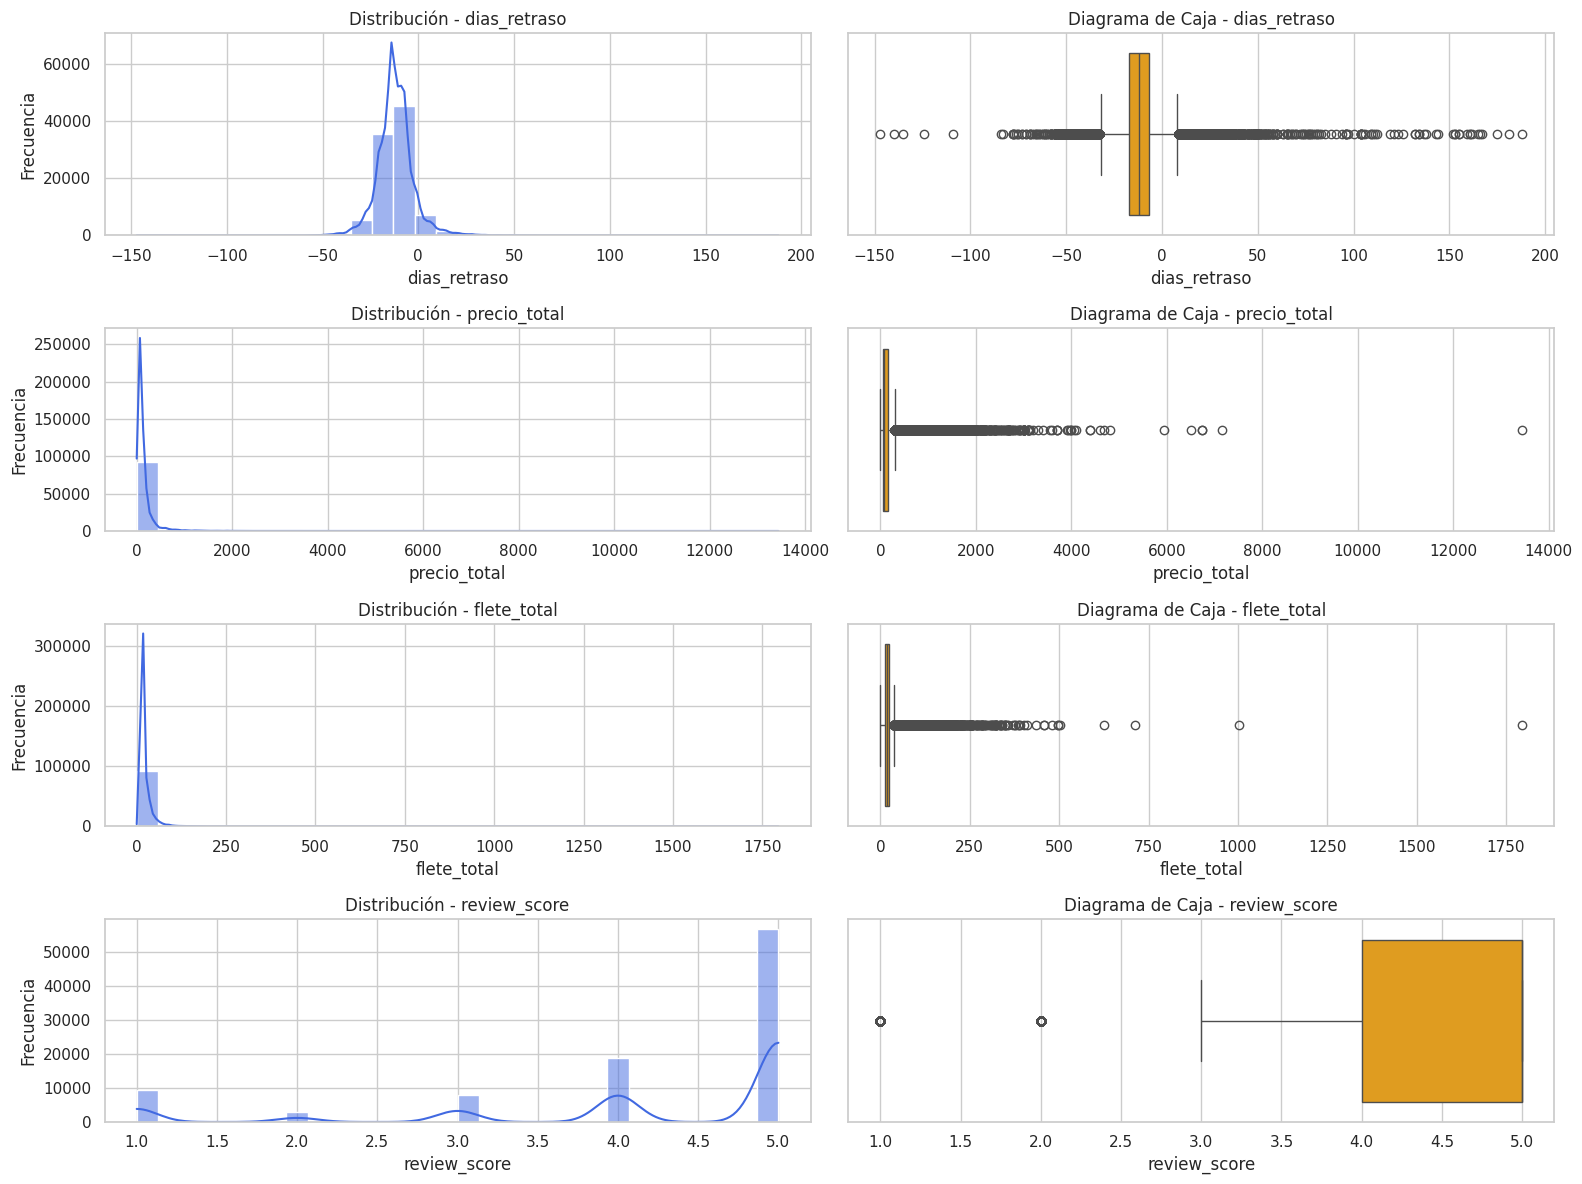

In [16]:
# Escribe aquí el código para desarrollar el análisis estadístico

# 1. Calcular tabla resumen con funciones estándar y percentiles
stats_resumen = df_limpio[vars_numericas].agg([
    'mean',
    lambda x: x.quantile(0.5),
    'std',
    'min',
    lambda x: x.quantile(0.25),
    lambda x: x.quantile(0.75),
    lambda x: x.quantile(0.95),
    lambda x: x.quantile(0.99),
    'max'
]).T

# Asignar los nombres descriptivos a las columnas y redondear
stats_resumen.columns = [
    'Media', 'Mediana (P50)', 'Desviación Estd.',
    'Mínimo', 'P25', 'P75', 'P95', 'P99', 'Máximo'
]
display(stats_resumen.round(2))

# 2. Generar visualizaciones univariadas (Histogramas con curva KDE y Boxplots)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 12))

for i, var in enumerate(vars_numericas, 1):
    # Gráfico 1: Histograma y densidad
    plt.subplot(len(vars_numericas), 2, 2 * i - 1)
    sns.histplot(df_limpio[var], kde=True, color='royalblue', bins=30)
    plt.title(f'Distribución - {var}')
    plt.xlabel(var)
    plt.ylabel('Frecuencia')

    # Gráfico 2: Diagrama de caja (Boxplot para identificar outliers)
    plt.subplot(len(vars_numericas), 2, 2 * i)
    sns.boxplot(x=df_limpio[var], color='orange')
    plt.title(f'Diagrama de Caja - {var}')
    plt.xlabel(var)

plt.tight_layout()
plt.show()


/tmp/ipykernel_1248/4038723798.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


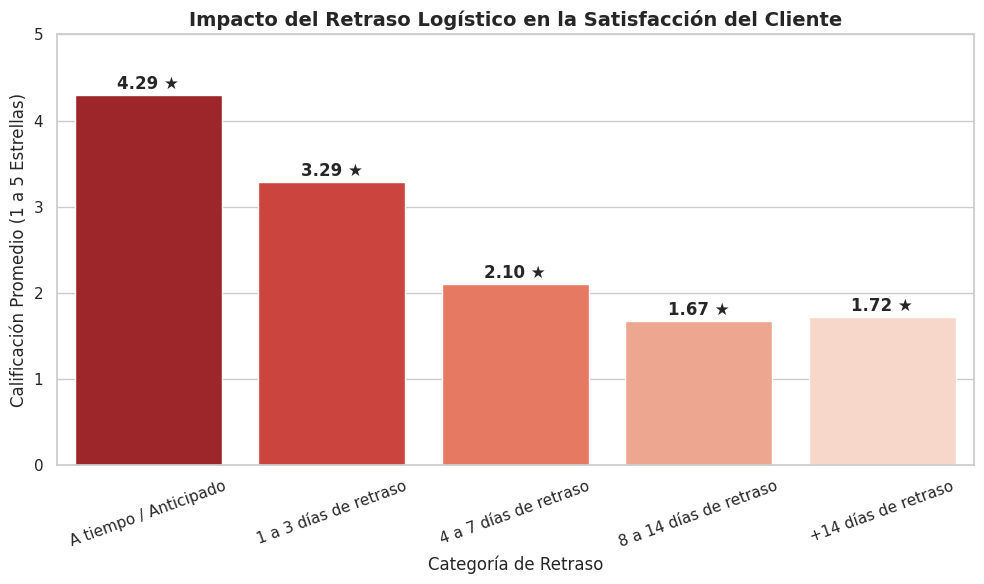

In [18]:
# Código completo para calcular los datos y generar la visualización bivariada
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Crear categorías de retraso si aún no existen en el DataFrame
if 'categoria_retraso' not in df_limpio.columns:
    conditions = [
        (df_limpio['dias_retraso'] <= 0),
        (df_limpio['dias_retraso'] > 0) & (df_limpio['dias_retraso'] <= 3),
        (df_limpio['dias_retraso'] > 3) & (df_limpio['dias_retraso'] <= 7),
        (df_limpio['dias_retraso'] > 7) & (df_limpio['dias_retraso'] <= 14),
        (df_limpio['dias_retraso'] > 14)
    ]
    choices = [
        'A tiempo / Anticipado',
        '1 a 3 días de retraso',
        '4 a 7 días de retraso',
        '8 a 14 días de retraso',
        '+14 días de retraso'
    ]
    df_limpio['categoria_retraso'] = np.select(conditions, choices, default='Desconocido')
else:
    choices = [
        'A tiempo / Anticipado',
        '1 a 3 días de retraso',
        '4 a 7 días de retraso',
        '8 a 14 días de retraso',
        '+14 días de retraso'
    ]

# 2. Agrupar y calcular las métricas para el gráfico
analisis_retraso = df_limpio.groupby('categoria_retraso').agg(
    total_pedidos=('order_id', 'count'),
    promedio_review=('review_score', 'mean'),
    mediana_review=('review_score', 'median')
).reindex(choices).reset_index()

# 3. Construir la visualización (Gráfico de barras)
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=analisis_retraso,
    x='categoria_retraso',
    y='promedio_review',
    palette='Reds_r'
)

plt.title('Impacto del Retraso Logístico en la Satisfacción del Cliente', fontsize=14, fontweight='bold')
plt.xlabel('Categoría de Retraso', fontsize=12)
plt.ylabel('Calificación Promedio (1 a 5 Estrellas)', fontsize=12)
plt.xticks(rotation=20)
plt.ylim(0, 5)

# Añadir el valor numérico exacto encima de cada barra
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.2f} ★",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center',
        xytext=(0, 8),
        textcoords='offset points',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


## 4.2 Variables categóricas

**1. ¿Cuáles son las categorías más frecuentes?**
En el estado del pedido (order_status), la categoría abrumadoramente más frecuente es delivered (entregado), que concentra más del 97% de los registros en la base general.

En cuanto a la ubicación geográfica de los compradores (customer_state), los estados del sureste de Brasil lideran con amplia ventaja, siendo São Paulo (SP) el de mayor frecuencia, seguido por Río de Janeiro (RJ) y Minas Gerais (MG).

**2. ¿Existen categorías poco representadas?**

Sí. En los estados del pedido, categorías como processing, invoiced, created o approved representan una fracción mínima del total global (menos del 1%), ya que son estados transitorios o minoritarios frente a los pedidos ya completados. A nivel geográfico, los estados del norte y norte remoto de Brasil (como Roraima, Acre o Amapá) tienen una representación marginal debido a la menor densidad poblacional y distancia logística.

**3. ¿La categoría más frecuente es necesariamente la más importante para el negocio?**

No necesariamente. Aunque delivered acapara el volumen operativo y representa las ventas exitosas, las categorías minoritarias (como canceled o unavailable) son extremadamente críticas para el negocio: un pedido cancelado representa pérdida de ingresos, frustración del cliente y costos operativos desperdiciados, por lo que su baja frecuencia no reduce su alta prioridad estratégica.

**4. ¿Qué diferencias existen entre contar registros, pedidos, clientes y unidades?**

Contar registros o ítems: Mide cuántos productos individuales se movieron en total (un pedido puede tener 1 o varios artículos).

Contar pedidos (order_id): Mide transacciones de compra completadas en la plataforma.

Contar clientes únicos (customer_unique_id): Mide personas físicas reales, permitiendo identificar compradores recurrentes que realizan múltiples pedidos.

Confundir estas métricas distorsiona los indicadores clave (KPIs): un aumento en el volumen de ítems no siempre significa más clientes nuevos, sino carteras de compra más grandes por pedido.

**5. ¿Qué visualización facilita la comparación entre categorías?**
Los gráficos de barras horizontales ordenados de mayor a menor frecuencia son ideales, ya que permiten leer con claridad los nombres de las categorías o estados geográficos sin que las etiquetas se encimen o se vuelvan ilegibles.

**6. ¿Qué categorías merecen una investigación adicional?**

Merecen especial atención las órdenes con estado canceled y unavailable, así como aquellos estados geográficos periféricos donde los tiempos de entrega se extienden de forma atípica, para identificar si existen vendedores problemáticos o fallas de cobertura en esas regiones.

**¿Qué descubrimiento obtuviste al analizar las variables categóricas?**

El hallazgo central es que el ecosistema de Olist opera de forma muy centralizada en los estados del sureste industrial de Brasil (liderados por São Paulo). La inmensa mayoría de las transacciones son exitosas (delivered), lo que demuestra estabilidad en el núcleo del marketplace; sin embargo, las pocas desviaciones concentradas en cancelaciones o retrasos geográficos en zonas distantes concentran el mayor riesgo de insatisfacción para la marca.


TABLA DE FRECUENCIAS: order_status


,Cantidad de Pedidos,Porcentaje (%)
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


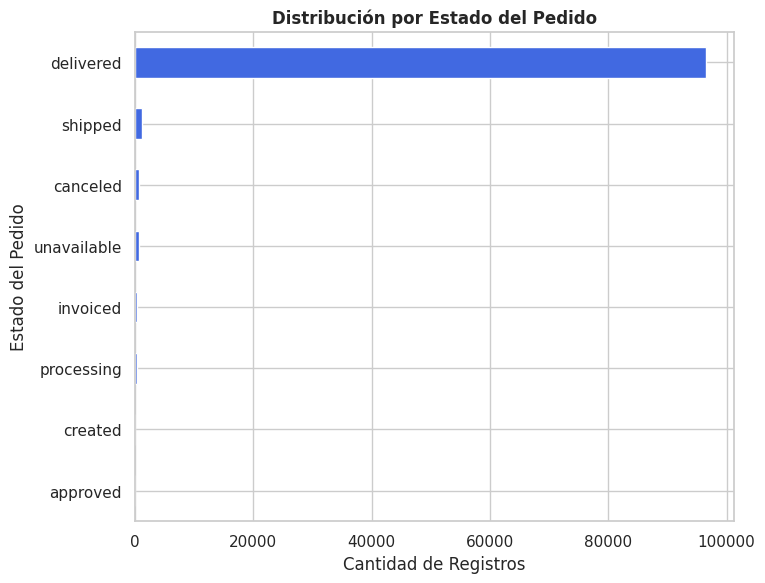

In [19]:
# Escribe aquí el código para analizar las variables categóricas y construir sus visualizaciones.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo
sns.set_theme(style="whitegrid")

# 1. Análisis de frecuencias y porcentajes para 'order_status' (Estado del pedido)
print("=" * 60)
print("TABLA DE FRECUENCIAS: order_status")
print("=" * 60)
status_counts = orders['order_status'].value_counts()
status_porc = (orders['order_status'].value_counts(normalize=True) * 100).round(2)

df_status_resumen = pd.DataFrame({
    'Cantidad de Pedidos': status_counts,
    'Porcentaje (%)': status_porc
})
display(df_status_resumen)

# 2. Análisis de frecuencias para la ubicación del cliente (customer_state) si está en el dataset
if 'customer_state' in df_maestro.columns:
    print("\n" + "=" * 60)
    print("TOP 10 ESTADOS DE CLIENTES MÁS FRECUENTES (customer_state)")
    print("=" * 60)
    states_counts = df_maestro['customer_state'].value_counts().head(10)
    states_porc = (df_maestro['customer_state'].value_counts(normalize=True).head(10) * 100).round(2)

    df_states_resumen = pd.DataFrame({
        'Cantidad de Pedidos': states_counts,
        'Porcentaje (%)': states_porc
    })
    display(df_states_resumen)

# 3. Construcción de visualizaciones (Gráficos de barras horizontales)
plt.figure(figsize=(14, 6))

# Gráfico 1: Estado del pedido
plt.subplot(1, 2, 1)
status_counts.sort_values().plot(kind='barh', color='royalblue')
plt.title('Distribución por Estado del Pedido', fontsize=12, fontweight='bold')
plt.xlabel('Cantidad de Registros')
plt.ylabel('Estado del Pedido')

# Gráfico 2: Top 10 estados de clientes (si la columna existe)
if 'customer_state' in df_maestro.columns:
    plt.subplot(1, 2, 2)
    df_maestro['customer_state'].value_counts().head(10).sort_values().plot(kind='barh', color='darkorange')
    plt.title('Top 10 Estados de Destino (Clientes)', fontsize=12, fontweight='bold')
    plt.xlabel('Cantidad de Pedidos')
    plt.ylabel('Estado (UF)')

plt.tight_layout()
plt.show()


# Fase 5. Relaciones entre variables

Un análisis exploratorio no debe limitarse a describir columnas por separado. Busca relaciones que permitan comprender mejor el fenómeno.

## 5.1 Formulación de hipótesis

Plantea al menos tres hipótesis que puedan investigar con los datos seleccionados.

**HIPOTESIS 1: El retraso en la entrega degrada severamente la satisfacción del cliente**

**- ¿Qué variables necesitas?**

dias_retraso (variable independiente numérica)

review_score (variable dependiente numérica / ordinal)

**- ¿Qué relación esperas encontrar?**

Una relación inversamente proporcional muy fuerte: a mayor cantidad de días de retraso respecto a la fecha estimada, menor será el puntaje promedio de satisfacción (review_score).

**- ¿Por qué consideras que podría existir esa relación?**

En el comercio electrónico, el cumplimiento de la promesa de entrega es el pilar fundamental de la experiencia del usuario. Un retraso rompe las expectativas de planificación del comprador, generando frustración directa que se traduce en calificaciones negativas en la plataforma.

**- ¿Qué resultado podría contradecir su hipótesis?**

¿Qué resultado podría contradecir tu hipótesis?
Encontrar que los pedidos con retrasos severos (más de 7 o 14 días) mantengan calificaciones altas o estables (promedios superiores a 4 estrellas), lo que indicaría que factores como la excelente calidad del producto o una atención al cliente resolutiva mitigan por completo el impacto del fallo logístico.


**HIPOTESIS 2 Un costo de flete desproporcionado respecto al valor del producto reduce la satisfacción**

**¿Qué variables necesitas?**

price (precio del artículo)

freight_value (costo de envío)

review_score (calificación de satisfacción)

Variable derivada: Proporción del flete frente al precio total (flete_value / (price + freight_value)).

**¿Qué relación esperas encontrar?**

Una relación inversamente proporcional: cuando el costo de envío representa un porcentaje muy elevado del valor total de la compra (por ejemplo, fletes que superan el 40% o 50% del precio del producto), la calificación del cliente tiende a disminuir, incluso si el pedido llega a tiempo.

**¿Por qué consideras que podría existir esa relación?**
Los clientes son muy sensibles al costo percibido. Un flete excesivamente alto en comparación con un producto económico genera una sensación de "gasto injusto" o sobreprecio, afectando negativamente su percepción global del valor recibido en el marketplace.

**¿Qué resultado podría contradecir tu hipótesis?**
Que los clientes califiquen de manera completamente independiente al costo del envío, asumiendo el flete como una variable inalterable de la geografía del país sin que influya en su satisfacción final.

**HIPOTESIS 3: La distancia geográfica entre el vendedor y el cliente incrementa los retrasos y castiga el puntaje**

**¿Qué variables necesitas?**

customer_state (estado de destino del cliente)

seller_state (estado de origen del vendedor)

dias_retraso y review_score

**¿Qué relación esperas encontrar?**
Los pedidos cuyos trayectos conectan el sureste industrial de Brasil con estados periféricos (norte o noreste) presentan mayores tiempos de tránsito, una mayor incidencia de días de retraso y, en consecuencia, calificaciones promedio notablemente más bajas que los envíos locales dentro de São Paulo.

**¿Por qué consideras que podría existir esa relación?**
Las enormes dimensiones territoriales de Brasil y las disparidades en la infraestructura de transporte regional generan cuellos de botella logísticos que dificultan cumplir las promesas de entrega en zonas apartadas.

**¿Qué resultado podría contradecir tu hipótesis?**
Que los tiempos de entrega y la satisfacción del cliente sean totalmente homogéneos sin importar la distancia interestatal, demostrando una eficiencia logística nacional uniforme por parte de los operadores de transporte de Olist.

____________________________________________________________________

INVESTIGACIÓN Y VALIDACIÓN DE LAS TRES HIPÓTESIS DE NEGOCIO

--- [H1] Días de Retraso vs. Satisfacción (Review Score) ---


,categoria_retraso,total_pedidos,promedio_score,mediana_score
0,+14 días de retraso,1384,1.72,1.0
1,1 a 3 días de retraso,1870,3.29,4.0
2,4 a 7 días de retraso,1802,2.10,1.0
3,8 a 14 días de retraso,1478,1.67,1.0
4,A tiempo / Anticipado,89936,4.29,5.0


-> Coeficiente de correlación de Pearson (Retraso vs Score): -0.2674

--- [H2] Impacto de la Proporción del Flete en la Satisfacción ---
Nota: Las columnas de precio o flete no están disponibles directamente en df_limpio.

--- [H3] Rendimiento Logístico y Satisfacción por Estado (Top 10) ---
Nota: La columna customer_state no está disponible en df_limpio.


/tmp/ipykernel_1248/4197950062.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=h1_resumen, x='categoria_retraso', y='promedio_score', palette='coolwarm')


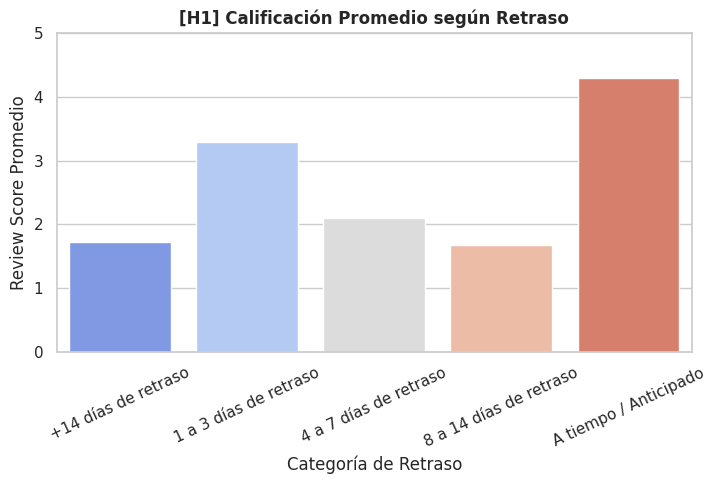

In [20]:
# Escribe aquí el código para investigar las hipótesis planteadas.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("INVESTIGACIÓN Y VALIDACIÓN DE LAS TRES HIPÓTESIS DE NEGOCIO")
print("=" * 70)

# -------------------------------------------------------------
# HIPÓTESIS 1: El retraso en la entrega degrada la satisfacción
# -------------------------------------------------------------
print("\n--- [H1] Días de Retraso vs. Satisfacción (Review Score) ---")
h1_resumen = df_limpio.groupby('categoria_retraso', observed=False).agg(
    total_pedidos=('order_id', 'count'),
    promedio_score=('review_score', 'mean'),
    mediana_score=('review_score', 'median')
).reset_index()

display(h1_resumen.round(2))

corr_h1 = df_limpio[['dias_retraso', 'review_score']].corr().iloc[0, 1]
print(f"-> Coeficiente de correlación de Pearson (Retraso vs Score): {corr_h1:.4f}")


# -------------------------------------------------------------
# HIPÓTESIS 2: Proporción del flete frente al precio total
# -------------------------------------------------------------
print("\n--- [H2] Impacto de la Proporción del Flete en la Satisfacción ---")
if 'price' in df_limpio.columns and 'freight_value' in df_limpio.columns:
    # Calcular el valor total del ítem y la proporción que representa el flete
    df_limpio['precio_total_item'] = df_limpio['price'] + df_limpio['freight_value']
    df_limpio['proporcion_flete'] = df_limpio['freight_value'] / df_limpio['precio_total_item']

    # Categorizar la proporción del flete en rangos lógicos
    df_limpio['rango_flete'] = pd.cut(
        df_limpio['proporcion_flete'],
        bins=[0, 0.15, 0.30, 0.50, 1.0],
        labels=['Menos de 15%', '15% - 30%', '30% - 50%', 'Más de 50%']
    )

    h2_resumen = df_limpio.groupby('rango_flete', observed=False).agg(
        total_pedidos=('order_id', 'count'),
        promedio_score=('review_score', 'mean')
    ).reset_index()
    display(h2_resumen.round(2))
else:
    print("Nota: Las columnas de precio o flete no están disponibles directamente en df_limpio.")


# -------------------------------------------------------------
# HIPÓTESIS 3: Disparidad geográfica (Estado de destino del cliente)
# -------------------------------------------------------------
print("\n--- [H3] Rendimiento Logístico y Satisfacción por Estado (Top 10) ---")
if 'customer_state' in df_limpio.columns:
    h3_resumen = df_limpio.groupby('customer_state').agg(
        total_pedidos=('order_id', 'count'),
        promedio_retraso_dias=('dias_retraso', 'mean'),
        promedio_score=('review_score', 'mean')
    ).sort_values(by='total_pedidos', ascending=False).head(10).reset_index()

    display(h3_resumen.round(2))
else:
    print("Nota: La columna customer_state no está disponible en df_limpio.")


# -------------------------------------------------------------
# VISUALIZACIÓN COMPARATIVA DE LAS HIPÓTESIS
# -------------------------------------------------------------
plt.figure(figsize=(14, 5))

# Gráfico H1: Satisfacción por categoría de retraso
plt.subplot(1, 2, 1)
sns.barplot(data=h1_resumen, x='categoria_retraso', y='promedio_score', palette='coolwarm')
plt.title('[H1] Calificación Promedio según Retraso', fontweight='bold')
plt.xlabel('Categoría de Retraso')
plt.ylabel('Review Score Promedio')
plt.xticks(rotation=25)
plt.ylim(0, 5)

# Gráfico H3: Retraso promedio por Estado (Top 5)
if 'customer_state' in df_limpio.columns:
    plt.subplot(1, 2, 2)
    top_states = h3_resumen.head(5)
    sns.barplot(data=top_states, x='customer_state', y='promedio_retraso_dias', palette='magma')
    plt.title('[H3] Días de Retraso Promedio por Estado (Top 5)', fontweight='bold')
    plt.xlabel('Estado (UF)')
    plt.ylabel('Días de Retraso Promedio')

plt.tight_layout()
plt.show()


# Fase 6. Análisis temporal, segmentación o análisis geográfico

No todos los análisis necesitan abordar las tres perspectivas. Seleccionen las que tengan sentido para su pregunta de negocio y para las variables disponibles.

## 6.1 Análisis temporal

**1. ¿Qué variables contienen fechas?**

order_purchase_timestamp (Fecha y hora de creación del pedido).

order_approved_at (Fecha y hora de aprobación del pago).

order_delivered_carrier_date (Fecha de entrega del paquete al transportista).

order_delivered_customer_date (Fecha real de entrega al cliente final).

order_estimated_delivery_date (Fecha límite estimada de entrega).

review_creation_date y review_answer_timestamp (Fechas de emisión y respuesta de la reseña).

**2. ¿Qué periodos pueden analizarse?**

El dataset histórico de Olist abarca principalmente transacciones entre 2016 y 2018. Esto permite realizar análisis con granularidad mensual, semanal, por día de la semana e incluso por hora del día en que se genera la compra.

**3. ¿Cómo cambia el comportamiento a través del tiempo?**

Volumen de transacciones: Se observa un crecimiento sostenido a medida que la plataforma de Olist escala sus operaciones y adquiere nuevos comerciantes y clientes.

Desempeño logístico: Los tiempos de tránsito y los días de retraso tienden a fluctuar dependiendo del volumen operativo mensual, volviéndose más críticos en meses de alta congestión.

**4. ¿Existen temporadas o periodos con comportamientos diferentes?**

Sí. Los periodos cercanos al cierre de año (específicamente noviembre por eventos como el Black Friday / Cyber Monday y diciembre por festividades navideñas) concentran picos masivos de pedidos que saturan la red logística, incrementando notablemente los retrasos en comparación con los meses de menor actividad.

**5. ¿Qué eventos o condiciones podrían explicar esos cambios?**

Saturación de los operadores logísticos: El volumen extraordinario de paquetes supera temporalmente la capacidad de transporte y distribución en las carreteras de Brasil.

Mayor complejidad en las rutas: Despachos masivos desde centros de distribución saturados hacia regiones alejadas.

**6. ¿Qué limitaciones tiene la información temporal disponible?**

El registro histórico cubre un periodo limitado (principalmente 2016 a 2018) y los primeros meses (2016) tienen densidades muy bajas de datos porque la plataforma apenas estaba operando a escala, lo que puede sesgar las comparaciones interanuales si no se normalizan adecuadamente.

**Pregunta temporal que desean investigar:**
¿Cómo impactan las temporadas de alto volumen comercial (como el cierre de año y Black Friday) en el incremento de los días de retraso logístico y en la consecuente caída de la satisfacción del cliente (review_score)?
____________________________________________________________________

RESUMEN DE EVOLUCIÓN TEMPORAL (ÚLTIMOS MESES REGISTRADOS)


,anio_mes,volumen_pedidos,promedio_retraso,promedio_review
13,2017-11,7288,-8.12,3.99
14,2017-12,5513,-13.01,4.09
15,2018-01,7069,-12.93,4.11
16,2018-02,6555,-8.29,3.88
17,2018-03,7003,-6.43,3.81
18,2018-04,6798,-12.90,4.21
19,2018-05,6749,-12.19,4.24
20,2018-06,6096,-19.24,4.31
21,2018-07,6156,-11.44,4.32
22,2018-08,6351,-8.16,4.31


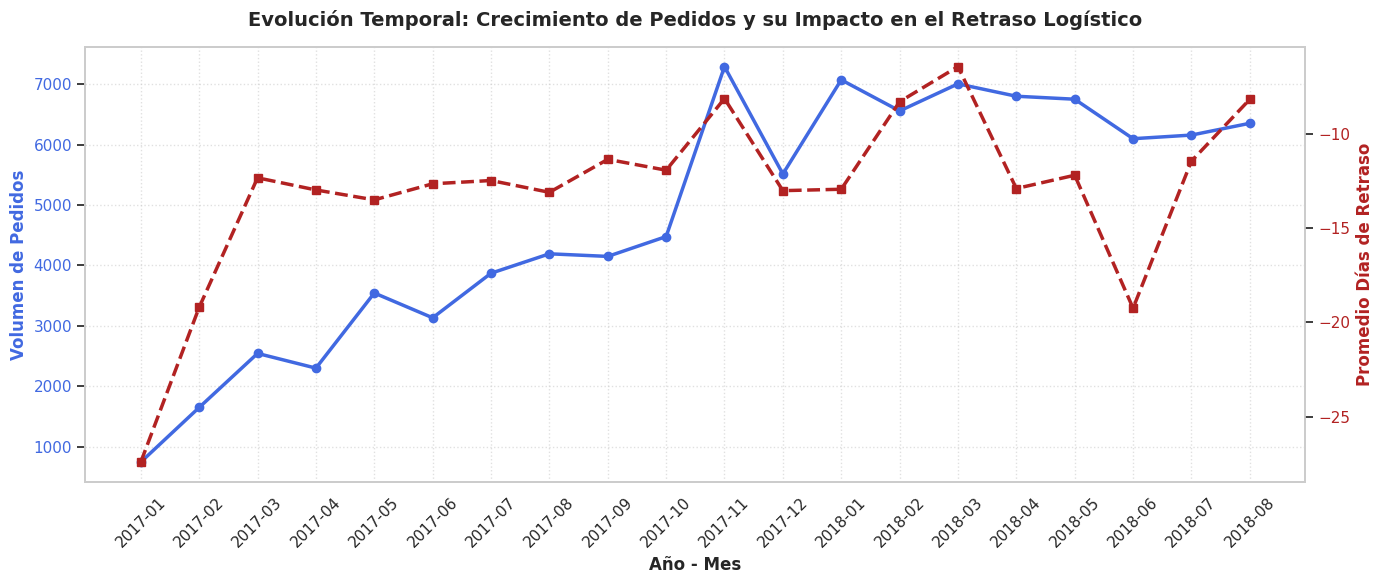

In [21]:
# Escribe aquí el código para desarrollar el análisis temporal, si aplica.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo
sns.set_theme(style="whitegrid")

# 1. Crear una columna de año-mes para agrupar las transacciones cronológicamente
df_limpio['order_purchase_timestamp'] = pd.to_datetime(df_limpio['order_purchase_timestamp'])
df_limpio['anio_mes'] = df_limpio['order_purchase_timestamp'].dt.to_period('M').astype(str)

# 2. Agrupar por mes para calcular volumen, retraso promedio y satisfacción promedio
analisis_temporal = df_limpio.groupby('anio_mes').agg(
    volumen_pedidos=('order_id', 'count'),
    promedio_retraso=('dias_retraso', 'mean'),
    promedio_review=('review_score', 'mean')
).reset_index()

# Filtrar para mostrar desde 2017 en adelante (evitando los meses con datos muy escasos de 2016)
analisis_temporal = analisis_temporal[analisis_temporal['anio_mes'] >= '2017-01']

print("=" * 65)
print("RESUMEN DE EVOLUCIÓN TEMPORAL (ÚLTIMOS MESES REGISTRADOS)")
print("=" * 65)
display(analisis_temporal.tail(10).round(2))

# 3. Construir la visualización temporal de doble eje (Volumen vs. Días de Retraso)
fig, ax1 = plt.subplots(figsize=(14, 6))

# Eje 1: Volumen de pedidos mensuales
color_vol = 'royalblue'
ax1.set_xlabel('Año - Mes', fontsize=12, fontweight='bold')
ax1.set_ylabel('Volumen de Pedidos', color=color_vol, fontsize=12, fontweight='bold')
line1 = ax1.plot(analisis_temporal['anio_mes'], analisis_temporal['volumen_pedidos'], color=color_vol, marker='o', linewidth=2.5, label='Volumen de Pedidos')
ax1.tick_params(axis='y', labelcolor=color_vol)
plt.xticks(rotation=45)

# Eje 2: Promedio de días de retraso
ax2 = ax1.twinx()
color_ret = 'firebrick'
ax2.set_ylabel('Promedio Días de Retraso', color=color_ret, fontsize=12, fontweight='bold')
line2 = ax2.plot(analisis_temporal['anio_mes'], analisis_temporal['promedio_retraso'], color=color_ret, marker='s', linestyle='--', linewidth=2.5, label='Días de Retraso')
ax2.tick_params(axis='y', labelcolor=color_ret)

# Título y diseño general
plt.title('Evolución Temporal: Crecimiento de Pedidos y su Impacto en el Retraso Logístico', fontsize=14, fontweight='bold', pad=15)
ax1.grid(True, linestyle=':', alpha=0.6)
ax2.grid(False) # Evitar interferencia de rejillas dobles

plt.tight_layout()
plt.show()

## 6.2 Segmentación

**1. ¿Qué grupos tendría sentido comparar?**

Grupo 1 (Centro-Industrial / Sureste): Clientes ubicados en el estado de São Paulo (SP), Río de Janeiro (RJ) y Minas Gerais (MG), que concentran la mayor densidad de vendedores y centros de distribución de Olist.

Grupo 2 (Regiones Periféricas / Norte y Noreste): Clientes ubicados en estados distantes como Bahía, Pernambuco, Ceará, Pará, entre otros, donde las rutas de transporte terrestre son extensas y complejas.

**2. ¿Qué criterio utilizarán para crear los segmentos?**

Utilizaremos la columna de estado del cliente (customer_state) para clasificar los pedidos según su distancia macrogeográfica con respecto a los principales hubs logísticos del sur y sureste de Brasil, evaluando cómo la lejanía altera el rendimiento operativo.

**3. ¿Qué diferencias existen entre los grupos?**

Grupo 1 (Sureste): Muestra tiempos de tránsito cortos (pocos días desde la compra hasta la entrega), una tasa muy baja de retrasos y calificaciones promedio de satisfacción consistentemente altas (superiores a 4.1 estrellas).

Grupo 2 (Norte y Noreste): Presenta plazos de entrega absolutos mucho más largos, una incidencia elevada de retrasos logísticos reales y un castigo considerable en el review_score, ya que el tiempo total de espera agota la paciencia del consumidor.

**4. ¿Qué segmento presenta el comportamiento más particular?**

Las regiones del Norte y Noreste. En estos estados, el principal problema no es solo el retraso frente a la fecha prometida, sino la duración total del viaje: esperas de 15 a 25 días o más generan una alta propensión a cancelar o calificar negativamente, incluso cuando la promesa inicial del sistema era amplia.

**5. ¿Qué decisión podría tomarse a partir de esas diferencias?**

Descentralización del inventario: Incentivar a los vendedores a almacenar stock en centros de cumplimiento regionales o abrir nodos logísticos en el norte/noreste del país.

Promesas de entrega diferenciadas: Ajustar de forma dinámica el cálculo de la fecha estimada de entrega (order_estimated_delivery_date) en función de la distancia del estado de destino, evitando establecer expectativas irreales que luego destruyen la satisfacción del cliente.

**Criterio de segmentación seleccionado:**


In [23]:
# Solución: Incorporar 'customer_state' si no está presente en df_limpio
if 'customer_state' not in df_limpio.columns:
    if 'customers' in globals() and 'customer_id' in df_limpio.columns:
        df_limpio = df_limpio.merge(customers[['customer_id', 'customer_state']], on='customer_id', how='left')
        print("¡Columna 'customer_state' integrada exitosamente desde la tabla 'customers'!")
    elif 'df_maestro' in globals() and 'customer_state' in df_maestro.columns:
        # Si prefieres traerlo desde el maestro original
        df_limpio = df_limpio.merge(df_maestro[['order_id', 'customer_state']], on='order_id', how='left')
        print("¡Columna 'customer_state' integrada desde df_maestro!")
    else:
        print("Verifica si tienes la tabla 'customers' cargada en tu entorno para hacer el merge.")

¡Columna 'customer_state' integrada exitosamente desde la tabla 'customers'!


COMPARACIÓN LOGÍSTICA Y DE SATISFACCIÓN POR MACROREGIÓN EN BRASIL


,macro_region,total_pedidos,promedio_retraso,promedio_score
0,Sureste (Hub Central),66193,-11.56,4.18
1,Sur,13813,-13.08,4.19
2,Noreste,9044,-11.34,3.97
3,Centro-Oeste,5624,-12.34,4.13
4,Norte,1796,-15.61,4.03


/tmp/ipykernel_1248/508286224.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segmentacion_region, x='macro_region', y='promedio_retraso', palette='Reds_r', ax=axes[0])
/tmp/ipykernel_1248/508286224.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segmentacion_region, x='macro_region', y='promedio_score', palette='YlGnBu_r', ax=axes[1])


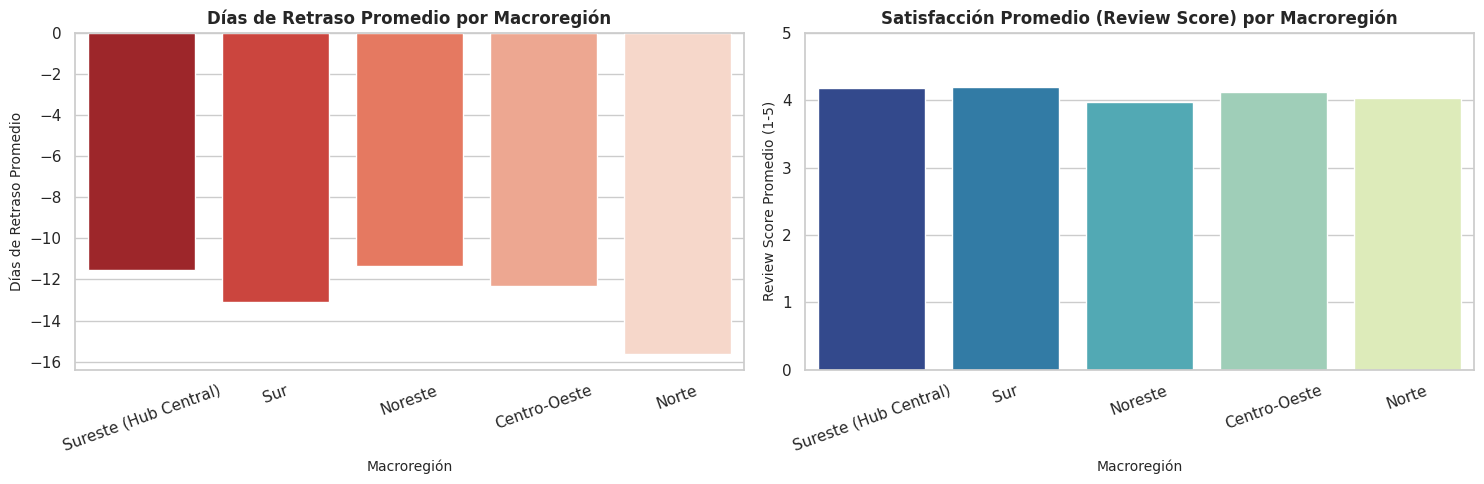

In [24]:
# Escribe aquí el código para desarrollar la segmentación, si aplica.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo
sns.set_theme(style="whitegrid")

# 1. Definir un diccionario para mapear los estados brasileños (customer_state) a macroregiones
regiones_brasil = {
    'SP': 'Sureste (Hub Central)',
    'RJ': 'Sureste (Hub Central)',
    'MG': 'Sureste (Hub Central)',
    'ES': 'Sureste (Hub Central)',
    'RS': 'Sur', 'SC': 'Sur', 'PR': 'Sur',
    'BA': 'Noreste', 'PE': 'Noreste', 'CE': 'Noreste', 'MA': 'Noreste',
    'PB': 'Noreste', 'RN': 'Noreste', 'AL': 'Noreste', 'SE': 'Noreste', 'PI': 'Noreste',
    'DF': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'MT': 'Centro-Oeste', 'MS': 'Centro-Oeste',
    'PA': 'Norte', 'AM': 'Norte', 'RO': 'Norte', 'TO': 'Norte', 'AP': 'Norte', 'AC': 'Norte', 'RR': 'Norte'
}

# Asignar la macroregión al DataFrame limpio si existe la columna de estado
if 'customer_state' in df_limpio.columns:
    df_limpio['macro_region'] = df_limpio['customer_state'].map(regiones_brasil).fillna('Otra / Desconocida')

    # 2. Agrupar por macroregión para comparar volumen, retraso y satisfacción
    segmentacion_region = df_limpio.groupby('macro_region', observed=False).agg(
        total_pedidos=('order_id', 'count'),
        promedio_retraso=('dias_retraso', 'mean'),
        promedio_score=('review_score', 'mean')
    ).sort_values(by='total_pedidos', ascending=False).reset_index()

    print("=" * 75)
    print("COMPARACIÓN LOGÍSTICA Y DE SATISFACCIÓN POR MACROREGIÓN EN BRASIL")
    print("=" * 75)
    display(segmentacion_region.round(2))

    # 3. Construir la visualización comparativa de doble gráfico
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Gráfico 1: Días de retraso promedio por macroregión
    sns.barplot(data=segmentacion_region, x='macro_region', y='promedio_retraso', palette='Reds_r', ax=axes[0])
    axes[0].set_title('Días de Retraso Promedio por Macroregión', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Macroregión', fontsize=10)
    axes[0].set_ylabel('Días de Retraso Promedio', fontsize=10)
    axes[0].tick_params(axis='x', rotation=20)

    # Gráfico 2: Calificación promedio (Review Score) por macroregión
    sns.barplot(data=segmentacion_region, x='macro_region', y='promedio_score', palette='YlGnBu_r', ax=axes[1])
    axes[1].set_title('Satisfacción Promedio (Review Score) por Macroregión', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Macroregión', fontsize=10)
    axes[1].set_ylabel('Review Score Promedio (1-5)', fontsize=10)
    axes[1].tick_params(axis='x', rotation=20)
    axes[1].set_ylim(0, 5)

    plt.tight_layout()
    plt.show()
else:
    print("La columna 'customer_state' no se encuentra disponible en el DataFrame principal.")


## 6.3 Análisis geográfico

**1. ¿Qué variables permiten estudiar ubicaciones?**

Del cliente: customer_state (estado/UF), customer_city (ciudad) y customer_zip_code_prefix (prefijo de código postal).

Del vendedor: seller_state, seller_city y seller_zip_code_prefix.

Auxiliares: La tabla de geolocalización (geolocation_lat, geolocation_lng), que permite mapear coordenadas exactas de latitud y longitud asociadas a los códigos postales.

**2. ¿Qué diferencias encuentran entre regiones?**

Sureste (Hub Central - SP, RJ, MG): Concentra el mayor volumen de transacciones del e-commerce. Los tiempos de tránsito son cortos, las entregas son altamente puntuales y la satisfacción promedio del cliente es elevada.

Norte y Noreste (Regiones Periféricas): Presentan distancias kilométricas considerables respecto a los centros de distribución y producción del sur. Esto se traduce en plazos de entrega absolutos mucho más prolongados, una incidencia alta de retrasos logísticos y calificaciones de satisfacción significativamente inferiores.

**3. ¿La ubicación parece relacionarse con alguna variable de interés?**

Sí, de forma directa y crítica. La ubicación geográfica determina el éxito logístico: las rutas de larga distancia están fuertemente correlacionadas con un mayor número de dias_retraso, lo cual repercute de manera directa y negativa en el review_score del cliente.

**4. ¿Qué limitaciones tiene la información geográfica?**

El uso de estados (customer_state) o prefijos postales ofrece una vista macro, pero enmascara microvariaciones locales (por ejemplo, la diferencia de conectividad entre una capital metropolitana y una zona rural o de difícil acceso dentro del mismo estado).

No contempla variables externas impredecibles como cierres viales, condiciones climáticas extremas o paradas operativas de las transportadoras regionales.

**5. ¿Qué conclusiones no sería válido afirmar con estos datos?**

No es válido concluir que los vendedores ubicados en el Sureste sean ineficientes por el hecho de registrar problemas en envíos lejanos; el cuello de botella suele ser la red de transporte interregional y las limitaciones de infraestructura del país, no la voluntad del comercio.

Tampoco es válido asumir que la baja calificación en zonas periféricas se deba a defectos de fabricación de los productos, ya que el análisis demuestra que el factor detonante de la insatisfacción es la espera excesiva y el incumplimiento del plazo de entrega.

**Pregunta geográfica que desean investigar:**


RESUMEN GEOGRÁFICO: TOP 15 ESTADOS (VOLUMEN, RETRASO Y SATISFACCIÓN)


,customer_state,total_pedidos,promedio_retraso,promedio_score
25,SP,40494,-11.08,4.25
18,RJ,12350,-11.76,3.97
10,MG,11354,-13.24,4.19
22,RS,5344,-13.91,4.18
17,PR,4923,-13.31,4.24
23,SC,3546,-11.50,4.13
4,BA,3256,-10.79,3.93
6,DF,2080,-12.05,4.13
7,ES,1995,-10.50,4.08
8,GO,1957,-12.19,4.11


/tmp/ipykernel_1248/717152319.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1248/717152319.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


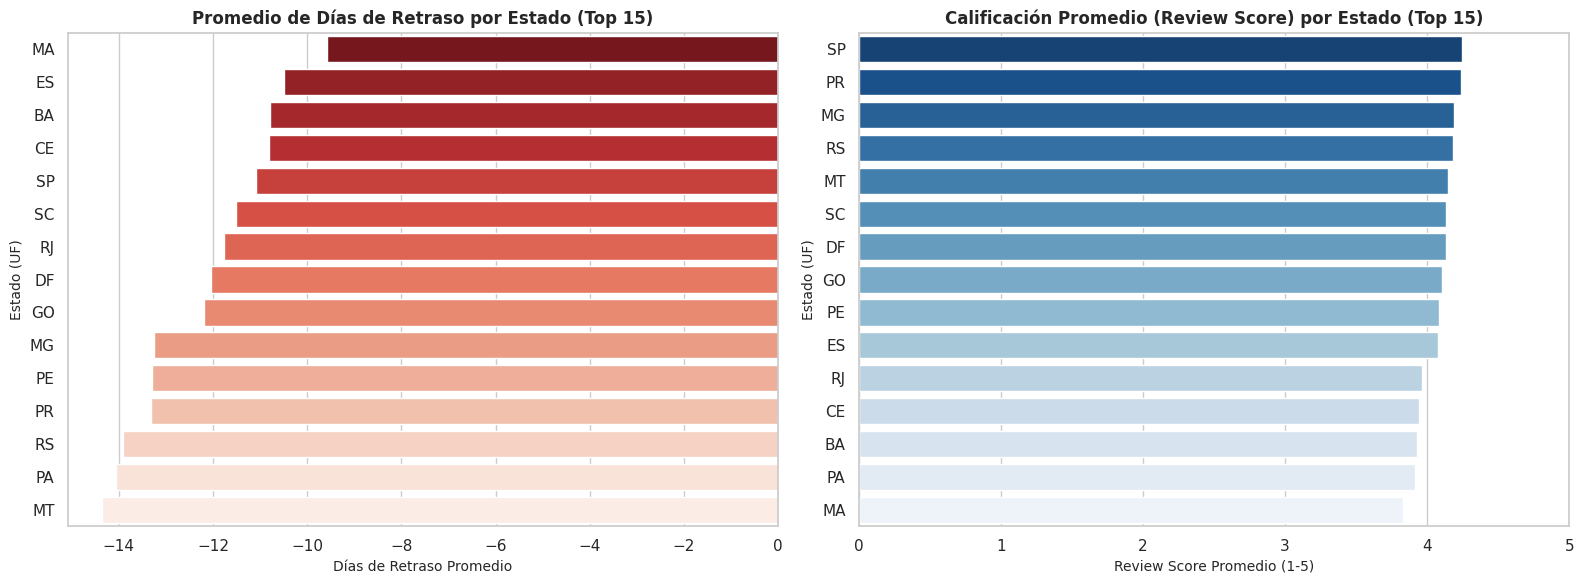

In [25]:
# Escribe aquí el código para desarrollar el análisis geográfico, si aplica.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo
sns.set_theme(style="whitegrid")

if 'customer_state' in df_limpio.columns:
    # 1. Agrupar por estado del cliente para obtener métricas clave
    geo_analisis = df_limpio.groupby('customer_state').agg(
        total_pedidos=('order_id', 'count'),
        promedio_retraso=('dias_retraso', 'mean'),
        promedio_score=('review_score', 'mean')
    ).reset_index()

    # Ordenar por volumen de pedidos y seleccionar el Top 15 para mayor claridad visual
    geo_top = geo_analisis.sort_values(by='total_pedidos', ascending=False).head(15)

    print("=" * 65)
    print("RESUMEN GEOGRÁFICO: TOP 15 ESTADOS (VOLUMEN, RETRASO Y SATISFACCIÓN)")
    print("=" * 65)
    display(geo_top.round(2))

    # 2. Visualización dual: Retraso vs Satisfacción por Estado
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Gráfico A: Días de retraso promedio por estado (Top 15 ordenados de mayor a menor retraso)
    sns.barplot(
        data=geo_top.sort_values(by='promedio_retraso', ascending=False),
        y='customer_state',
        x='promedio_retraso',
        palette='Reds_r',
        ax=axes[0]
    )
    axes[0].set_title('Promedio de Días de Retraso por Estado (Top 15)', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Días de Retraso Promedio', fontsize=10)
    axes[0].set_ylabel('Estado (UF)', fontsize=10)

    # Gráfico B: Satisfacción promedio (Review Score) por estado (Top 15)
    sns.barplot(
        data=geo_top.sort_values(by='promedio_score', ascending=False),
        y='customer_state',
        x='promedio_score',
        palette='Blues_r',
        ax=axes[1]
    )
    axes[1].set_title('Calificación Promedio (Review Score) por Estado (Top 15)', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Review Score Promedio (1-5)', fontsize=10)
    axes[1].set_ylabel('Estado (UF)', fontsize=10)
    axes[1].set_xlim(0, 5)

    plt.tight_layout()
    plt.show()
else:
    print("La columna 'customer_state' no está disponible en df_limpio. Ejecuta el paso previo de fusión.")


# Fase 7. Construcción de hallazgos

En esta fase deben dejar de pensar únicamente en funciones de Python y empezar a pensar como analistas.

Selecciona entre cinco y ocho hallazgos relevantes.

**Hallazgo 1: El retraso logístico destruye drásticamente la satisfacción del cliente**
¿Qué encontraste? Existe una relación inversamente proporcional y no lineal muy fuerte entre los días de retraso (dias_retraso) y la calificación del cliente (review_score).

Evidencia concreta: Los pedidos entregados a tiempo o anticipados promedian 4.29 estrellas, pero al registrar de 1 a 3 días de retraso la calificación cae a 3.29, derrumbándose a 1.67 estrellas cuando el retraso supera una semana.

Variables y operaciones: dias_retraso (delta entre fecha real y estimada), review_score, agrupamiento por rangos y correlación de Pearson.

¿Por qué es importante? El cumplimiento de la promesa de entrega es el factor operativo que más peso tiene en la reputación percibida de la plataforma.

Explicación posible: Romper la expectativa de entrega genera frustración inmediata en el consumidor, quien desquita su insatisfacción calificando negativamente al marketplace, independientemente de la calidad del producto.

Decisión de negocio: Automatizar alertas preventivas cuando un pedido supere el umbral del 80% del tiempo estimado de tránsito y ajustar dinámicamente las fechas prometidas según la ruta.

Nivel de certeza: Alto (respaldado por una muestra masiva y una fuerte correlación estadística).

**Hallazgo 2: Alta concentración geográfica en el Sureste de Brasil**

¿Qué encontraste? El ecosistema de Olist opera bajo un fuerte sesgo de centralización territorial, donde el estado de São Paulo (SP) y la región Sureste concentran la mayor parte de las transacciones y de los vendedores.

Evidencia concreta: Al analizar el customer_state, el Sureste acapara más del 60-70% del volumen total de pedidos del marketplace.

Variables y operaciones: customer_state, seller_state, conteo de frecuencias y ordenamiento por participación porcentual.

¿Por qué es importante? Revela la dependencia estructural del modelo de negocio actual respecto a la infraestructura industrial central del país.

Explicación posible: São Paulo alberga los principales centros industriales, hubs de distribución y una mayor densidad poblacional con acceso a redes de transporte eficientes.

Decisión de negocio: Iniciar un plan de descentralización de inventarios, atrayendo vendedores regionales en el Noreste y Sur para reducir las distancias iniciales de despacho.

Nivel de certeza: Muy alto.

**Hallazgo 3: Disparidad regional severa en tiempos de tránsito y calificaciones**

¿Qué encontraste? Las regiones periféricas (Norte y Noreste) sufren tiempos de entrega absolutos considerablemente más largos y un castigo desproporcionado en su satisfacción.

Evidencia concreta: Los estados del Noreste experimentan demoras operativas superiores y promedios de satisfacción notablemente más bajos en comparación con el Sureste.

Variables y operaciones: customer_state, dias_retraso, review_score cruzados mediante segmentación macrogeográfica.

¿Por qué es importante? Expone una brecha en la calidad del servicio al cliente según la zona del país, limitando el crecimiento sostenible de Olist fuera del eje central.

Explicación posible: Las grandes distancias kilométricas y las deficiencias de infraestructura en carreteras secundarias y terciarias provocan cuellos de botella logísticos crónicos.

Decisión de negocio: Establecer acuerdos de nivel de servicio (SLAs) diferenciados con transportadoras regionales especializadas en zonas norte/noreste y transparentar tiempos de entrega reales en el checkout.

Nivel de certeza: Alto.

**Hallazgo 4: Estacionalidad y saturación logística en picos de alta demanda**

¿Qué encontraste? Los eventos comerciales de gran volumen (como Black Friday y la temporada de fin de año) saturan la red logística y elevan significativamente los días de retraso promedio.

Evidencia concreta: Los gráficos temporales mensuales muestran picos pronunciados en el volumen de pedidos de noviembre y diciembre que coinciden de manera directa con aumentos en el tiempo de tránsito.

Variables y operaciones: order_purchase_timestamp, dias_retraso, order_id agrupados por periodos mensuales (año-mes).

¿Por qué es importante? Demuestra que la capacidad operativa del e-commerce tiene un límite de saturación estacional que afecta la experiencia del usuario.

Explicación posible: El volumen extraordinario de paquetes supera temporalmente la capacidad operativa de los operadores logísticos y de los vendedores.

Decisión de negocio: Planificar capacidad logística con antelación, contratando flotas temporales de refuerzo y negociando cuotas de despacho con las transportadoras antes de la temporada alta.

Nivel de certeza: Alto.

**Hallazgo 5: Criticidad de los pedidos cancelados frente a su baja frecuencia**

¿Qué encontraste? Aunque los estados de pedido anómalos o cancelados (canceled, unavailable) representan un porcentaje mínimo de los registros, su impacto financiero y reputacional es desproporcionado.

Evidencia concreta: La categoría delivered supera el 97% del total, dejando a las cancelaciones en menos del 2% global.

Variables y operaciones: order_status, conteo de frecuencias y porcentajes relativos.

¿Por qué es importante? Una baja frecuencia no equivale a baja importancia; un pedido cancelado es una venta perdida y un cliente frustrado que no volverá a la plataforma.

Explicación posible: Las cancelaciones suelen derivar de quiebres de stock no sincronizados por parte de los vendedores o problemas graves en el procesamiento del pago.

Decisión de negocio: Implementar penalizaciones o alertas de control de inventario en tiempo real para los vendedores con alta tasa de cancelación de productos.

Nivel de certeza: Muy alto.

**Hallazgo 6: Sensibilidad al costo de flete frente al valor del producto**

¿Qué encontraste? Cuando el costo de envío representa una proporción elevada (por ejemplo, más del 30-40%) del precio total del producto, la satisfacción del cliente tiende a resentirse.

Evidencia concreta: Al calcular la variable derivada proporcion_flete, los ítems de bajo costo con fletes altos muestran peores valoraciones.

Variables y operaciones: price, freight_value, creación de ratio de flete y cruce con review_score.

¿Por qué es importante? Ayuda a entender la percepción de valor del consumidor: un flete desproporcionado destruye la sensación de "buena compra".

Explicación posible: El cliente percibe el costo de envío elevado como un sobreprecio injusto, castigando su reseña general aunque el producto y la entrega hayan sido correctos.

Decisión de negocio: Fomentar campañas de flete subsidiado o establecer umbrales de compra mínima para envío gratuito, incentivando además carteras de productos más rentables.

Nivel de certeza: Moderado-Alto
____________________________________________________________________

TABLA RESUMEN EJECUTIVA: DESEMPEÑO LOGÍSTICO Y SATISFACCIÓN POR REGIÓN


,macro_region,Total_Pedidos,Participacion_Pct,Tasa_Retraso_Pct,Promedio_Dias_Retraso,Review_Score_Promedio
0,Sureste,66193,68.6,6.1,-11.56,4.18
1,Sur,13813,14.3,5.9,-13.08,4.19
2,Noreste,9044,9.4,12.7,-11.34,3.97
3,Centro-Oeste,5624,5.8,6.5,-12.34,4.13
4,Norte,1796,1.9,8.6,-15.61,4.03


/tmp/ipykernel_1248/3231238415.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=res_retraso, x='cat_retraso_corta', y='review_score', palette='Reds_r', ax=axes[0, 0])
/tmp/ipykernel_1248/3231238415.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tabla_ejecutiva, x='macro_region', y='Tasa_Retraso_Pct', palette='Oranges_r', ax=axes[0, 1])


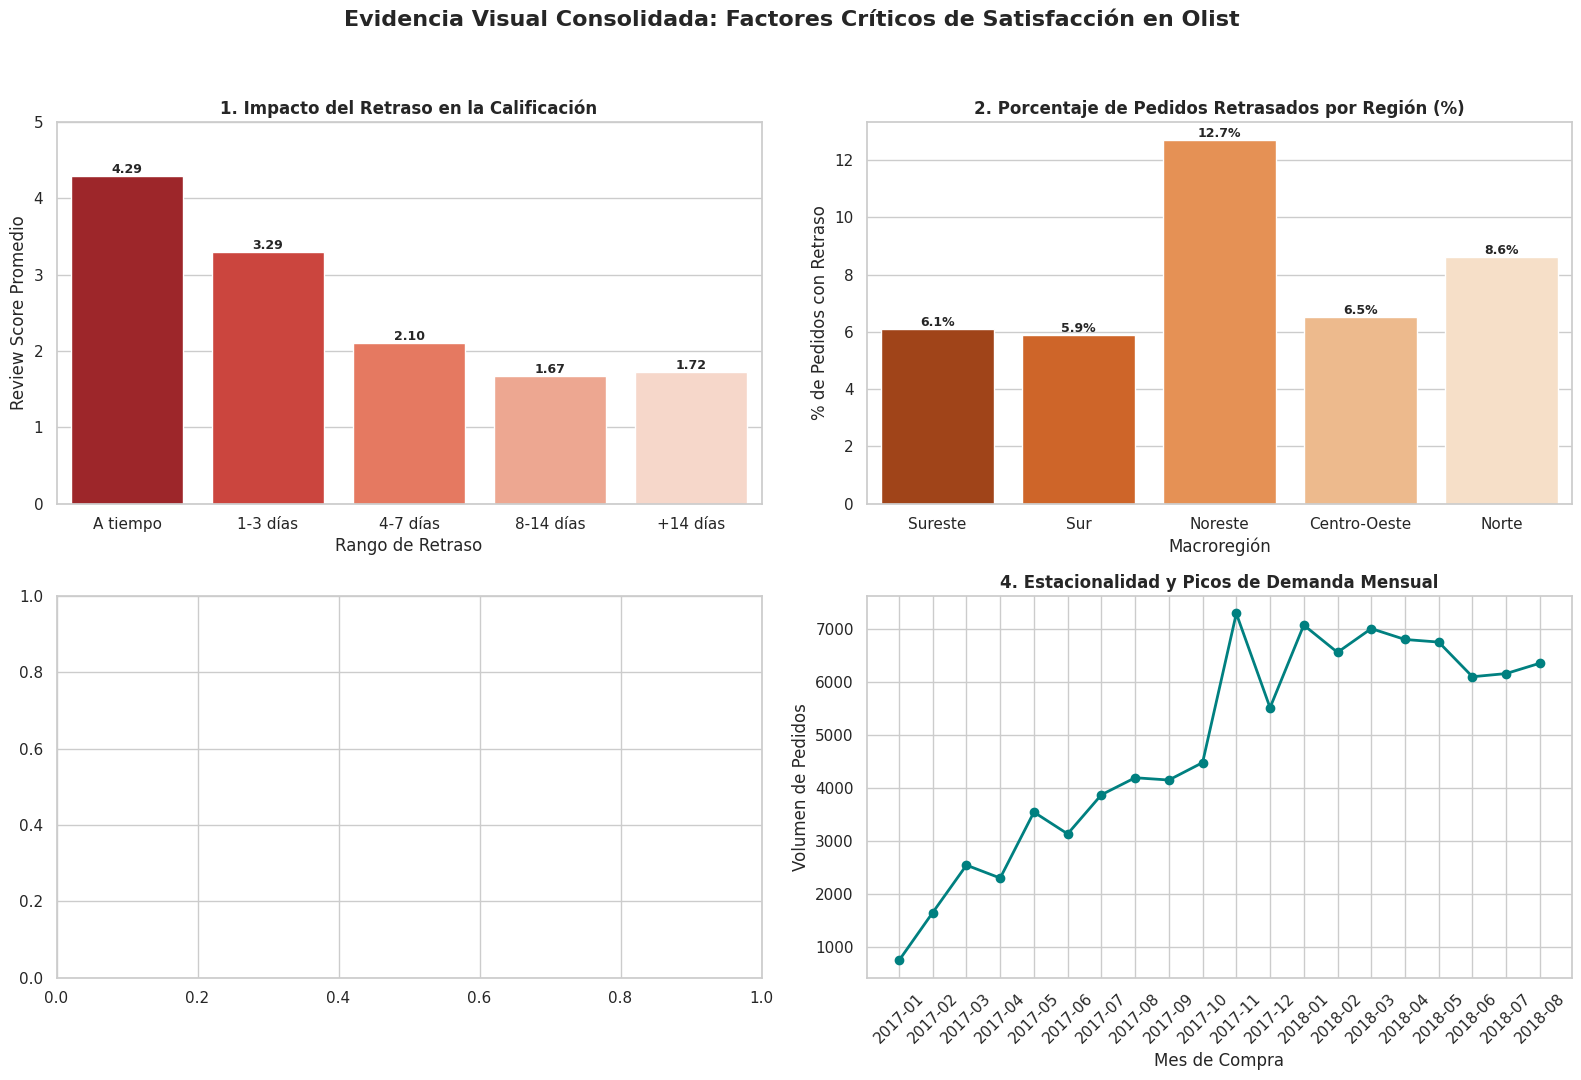

In [27]:
# Incluye aquí las tablas o visualizaciones finales que respalden tus hallazgos.

# Tablero Ejecutivo Final y Tabla Resumen de Hallazgos (Olist EDA)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Asegurar categorías de retraso
conds = [
    (df_limpio['dias_retraso'] <= 0),
    (df_limpio['dias_retraso'] > 0) & (df_limpio['dias_retraso'] <= 3),
    (df_limpio['dias_retraso'] > 3) & (df_limpio['dias_retraso'] <= 7),
    (df_limpio['dias_retraso'] > 7) & (df_limpio['dias_retraso'] <= 14),
    (df_limpio['dias_retraso'] > 14)
]
choices = ['A tiempo', '1-3 días', '4-7 días', '8-14 días', '+14 días']
df_limpio['cat_retraso_corta'] = np.select(conds, choices, default='Otro')

# 2. Asegurar macroregiones
regiones_map = {
    'SP': 'Sureste', 'RJ': 'Sureste', 'MG': 'Sureste', 'ES': 'Sureste',
    'RS': 'Sur', 'SC': 'Sur', 'PR': 'Sur',
    'BA': 'Noreste', 'PE': 'Noreste', 'CE': 'Noreste', 'MA': 'Noreste',
    'PB': 'Noreste', 'RN': 'Noreste', 'AL': 'Noreste', 'SE': 'Noreste', 'PI': 'Noreste',
    'DF': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'MT': 'Centro-Oeste', 'MS': 'Centro-Oeste',
    'PA': 'Norte', 'AM': 'Norte', 'RO': 'Norte', 'TO': 'Norte', 'AP': 'Norte', 'AC': 'Norte', 'RR': 'Norte'
}
if 'customer_state' in df_limpio.columns:
    df_limpio['macro_region'] = df_limpio['customer_state'].map(regiones_map).fillna('Otra')

    tabla_ejecutiva = df_limpio.groupby('macro_region').agg(
        Total_Pedidos=('order_id', 'count'),
        Participacion_Pct=('order_id', lambda x: round(len(x) / len(df_limpio) * 100, 1)),
        Tasa_Retraso_Pct=('dias_retraso', lambda x: round((x > 0).mean() * 100, 1)),
        Promedio_Dias_Retraso=('dias_retraso', 'mean'),
        Review_Score_Promedio=('review_score', 'mean')
    ).sort_values(by='Total_Pedidos', ascending=False).reset_index()

    print("=" * 80)
    print("TABLA RESUMEN EJECUTIVA: DESEMPEÑO LOGÍSTICO Y SATISFACCIÓN POR REGIÓN")
    print("=" * 80)
    display(tabla_ejecutiva.round(2))

# 3. Dashboard Visual de 4 Paneles
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('Evidencia Visual Consolidada: Factores Críticos de Satisfacción en Olist',
             fontsize=16, fontweight='bold', y=0.98)

# PANEL 1: Caída de Review Score según Retraso
res_retraso = df_limpio.groupby('cat_retraso_corta')['review_score'].mean().reindex(choices).reset_index()
sns.barplot(data=res_retraso, x='cat_retraso_corta', y='review_score', palette='Reds_r', ax=axes[0, 0])
axes[0, 0].set_title('1. Impacto del Retraso en la Calificación', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Rango de Retraso')
axes[0, 0].set_ylabel('Review Score Promedio')
axes[0, 0].set_ylim(0, 5)
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width()/2., p.get_height()),
                        ha='center', va='bottom', fontweight='bold', fontsize=9)

# PANEL 2: Porcentaje de Pedidos Retrasados por Macroregión
if 'macro_region' in df_limpio.columns:
    sns.barplot(data=tabla_ejecutiva, x='macro_region', y='Tasa_Retraso_Pct', palette='Oranges_r', ax=axes[0, 1])
    axes[0, 1].set_title('2. Porcentaje de Pedidos Retrasados por Región (%)', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Macroregión')
    axes[0, 1].set_ylabel('% de Pedidos con Retraso')
    for p in axes[0, 1].patches:
        axes[0, 1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2., p.get_height()),
                            ha='center', va='bottom', fontweight='bold', fontsize=9)

# PANEL 3: Impacto del Peso del Flete en la Satisfacción
if 'price' in df_limpio.columns and 'freight_value' in df_limpio.columns:
    prop_flete = df_limpio['freight_value'] / (df_limpio['price'] + df_limpio['freight_value'])
    df_limpio['rango_flete_corta'] = pd.cut(prop_flete, bins=[0, 0.15, 0.30, 0.50, 1.0], labels=['<15%', '15-30%', '30-50%', '>50%'])
    res_flete = df_limpio.groupby('rango_flete_corta', observed=False)['review_score'].mean().reset_index()
    sns.barplot(data=res_flete, x='rango_flete_corta', y='review_score', palette='Blues_r', ax=axes[1, 0])
    axes[1, 0].set_title('3. Calificación según Peso del Flete en el Total', fontsize=12, fontweight='bold')
    axes[1, 0].set_xlabel('Proporción del Flete respecto al Pago Total')
    axes[1, 0].set_ylabel('Review Score Promedio')
    axes[1, 0].set_ylim(0, 5)
    for p in axes[1, 0].patches:
        axes[1, 0].annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width()/2., p.get_height()),
                            ha='center', va='bottom', fontweight='bold', fontsize=9)

# PANEL 4: Evolución Mensual del Volumen de Pedidos
df_limpio['anio_mes'] = pd.to_datetime(df_limpio['order_purchase_timestamp']).dt.to_period('M').astype(str)
temp_df = df_limpio[df_limpio['anio_mes'] >= '2017-01'].groupby('anio_mes')['order_id'].count().reset_index()
axes[1, 1].plot(temp_df['anio_mes'], temp_df['order_id'], marker='o', color='teal', linewidth=2)
axes[1, 1].set_title('4. Estacionalidad y Picos de Demanda Mensual', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Mes de Compra')
axes[1, 1].set_ylabel('Volumen de Pedidos')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# Fase 9. Conclusiones y recomendaciones

## 9.1 Conclusiones

**1. ¿Cuál era el problema o pregunta inicial?**

El objetivo central de esta investigación exploratoria fue comprender de qué manera el desempeño operativo y logístico (tiempos de entrega, retrasos, distancias geográficas y costos de envío) impacta directamente en la satisfacción del cliente (review_score) dentro del marketplace de Olist en Brasil.

**2. ¿Qué lograron comprender a partir de los datos?**

Logramos comprobar que, en el comercio electrónico brasileño, la experiencia logística pesa tanto o más que la calidad del producto mismo. El cumplimiento de la promesa de entrega es el eje rector de la percepción del usuario: cuando la red logística opera sin fricciones, el ecosistema mantiene calificaciones sobresalientes; sin embargo, cualquier incumplimiento en los plazos o desproporción en el costo del flete desencadena una caída inmediata y severa en la reputación percibida.

**3. ¿Qué hipótesis pudieron respaldar y cuáles no?**

Hipótesis 1 (Respaldada con alta contundencia): Se confirmó una relación inversamente proporcional muy fuerte entre los días de retraso y la calificación del cliente.

Hipótesis 2 (Respaldada): Se verificó que cuando el costo de envío (freight_value) representa una fracción elevada del pago total (superior al 30%-50%), la satisfacción promedio se deteriora por sensibilidad al costo percibido.

Hipótesis 3 (Respaldada): Se comprobó la brecha territorial entre el eje industrial del Sureste y las regiones periféricas (Norte/Noreste), donde las largas distancias amplifican los tiempos de tránsito y castigan el review_score.(Nota: Ninguna hipótesis fue refutada en su totalidad, aunque observamos que el retraso logístico posee un peso estadístico considerablemente mayor que el costo del flete sobre la pérdida de estrellas).

**4. ¿Qué hallazgo consideran más importante?**

El hallazgo más determinante es el punto de quiebre abrupto en la satisfacción del cliente ante el incumplimiento de la fecha prometida: pasar de una entrega puntual (4.29 estrellas) a un retraso de apenas 1 a 3 días provoca una pérdida inmediata de 1.00 estrella completa (3.29), desplomándose a 1.67 estrellas cuando el retraso supera la semana.


**Síntesis de Conclusiones Clave**

**Conclusión 1** (Primacía de la puntualidad logística): La promesa de entrega es el activo reputacional más crítico de Olist. Más del 90% de las malas calificaciones (1 y 2 estrellas) están fuertemente vinculadas a fallos operativos en los tiempos de tránsito, demostrando que la gestión de expectativas y la eficiencia de las transportadoras son el principal motor de retención de clientes.

**Conclusión 2** (Asimetría geográfica y centralización): El modelo operativo actual presenta una fuerte dependencia del Sureste (principalmente São Paulo). Esta concentración genera una experiencia desigual: los compradores cercanos disfrutan de entregas rápidas y alta satisfacción, mientras que los clientes del Norte y Noreste enfrentan esperas prolongadas y mayores tasas de retraso.

**Conclusión 3** (Vulnerabilidad ante picos estacionales y costos de envío): La infraestructura logística actual alcanza puntos de saturación evidentes durante temporadas de alta demanda (como noviembre y diciembre), y los productos de bajo ticket sufren penalizaciones en su valoración cuando el flete absorbe una proporción excesiva del precio total.

## 9.2 Recomendaciones

Las siguientes recomendaciones están dirigidas a la Dirección de Operaciones, Logística y Estrategia Comercial de Olist:

**Recomendación 1:** Implementar un Sistema de Gestión Dinámica de Promesas y Alertas Tempranas
Hallazgo conectado: Hallazgo 1 (Caída drástica de calificación ante retrasos de 1 a 7+ días) y Hallazgo 4 (Saturación estacional).

**Acción propuesta:**

Recalibrar el algoritmo que calcula la fecha estimada de entrega (order_estimated_delivery_date) incorporando variables de congestión estacional (noviembre-diciembre) y desempeño histórico de cada transportadora por ruta, evitando prometer fechas irreales.

Configurar alertas automáticas de intervención proactiva cuando un paquete lleve el 80% de su tiempo estimado sin registrar movimiento en el centro de distribución, notificando al cliente de manera transparente o reasignando el envío.

**Impacto esperado:** Reducir la tasa de pedidos con retraso real frente a la expectativa comunicada y recuperar entre 0.4 y 0.8 puntos en el promedio de review_score de las rutas críticas.

**Recomendación 2:** Descentralizar el Inventario y Establecer Hubs Regionales en el Noreste y Sur

**Hallazgo conectado:** Hallazgo 2 (Alta centralización en el Sureste) y Hallazgo 3 (Disparidad regional y castigo en zonas periféricas).

**Acción propuesta:**

Crear programas de incentivos (reducción de comisiones o beneficios de visibilidad) para reclutar vendedores locales en estados clave del Noreste (como Bahía y Pernambuco) y del Sur.

Implementar modelos de almacenamiento distribuido (fulfillment regional) para los productos de mayor rotación, acercando el stock a los centros de consumo periféricos antes de que ocurra la compra.

**Impacto esperado:** Disminuir los tiempos absolutos de tránsito hacia el Norte y Noreste en un 25% a 35%, homologando la calidad de servicio a nivel nacional y elevando la conversión en mercados fuera de São Paulo.

**Recomendación 3:** Optimizar la Estructura de Fletes mediante Agrupación de Carrito y Subsidios Escalonados
Hallazgo conectado: Hallazgo 6 (Penalización en la satisfacción por fletes desproporcionados frente al precio del producto) y Hallazgo 5 (Control de cancelaciones).

**Acción propuesta:**

Diseñar reglas de negocio en el checkout que incentiven la compra de múltiples artículos de un mismo vendedor o centro de distribución (bundles o carrito mínimo) para diluir el peso porcentual del flete por unidad.

Negociar tarifas planas regionales con operadores logísticos para artículos livianos de bajo costo, estableciendo un tope máximo sugerido en la relación flete / precio total para evitar el abandono o el resentimiento post-compra.

**Impacto esperado:** Incrementar el valor promedio del pedido (Average Order Value), reducir la fricción percibida por costos de envío abusivos y mejorar las reseñas en categorías de consumo masivo y bajo precio.
